In [88]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("juhibhojani/airline-reviews")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'airline-reviews' dataset.
Path to dataset files: /kaggle/input/airline-reviews


In [89]:
# ============================================================
# STEP 1: INSPECT AND LOAD THE AIRLINE REVIEWS DATASET
# ============================================================

import os
import glob
import pandas as pd
from pathlib import Path

# Path returned by kagglehub
dataset_path = Path(path)

print("=" * 70)
print("DATASET DIRECTORY")
print("=" * 70)
print(dataset_path)

# ------------------------------------------------------------
# 1. Show all files available inside the downloaded dataset
# ------------------------------------------------------------

all_files = [
    file
    for file in dataset_path.rglob("*")
    if file.is_file()
]

print("\n" + "=" * 70)
print("FILES FOUND")
print("=" * 70)

for i, file in enumerate(all_files, start=1):
    size_mb = file.stat().st_size / (1024 ** 2)
    print(f"{i}. {file.name} ({size_mb:.2f} MB)")

# ------------------------------------------------------------
# 2. Locate CSV files
# ------------------------------------------------------------

csv_files = list(dataset_path.rglob("*.csv"))

print("\n" + "=" * 70)
print("CSV FILES")
print("=" * 70)

if len(csv_files) == 0:
    print("No CSV files were found.")
else:
    for i, file in enumerate(csv_files, start=1):
        print(f"{i}. {file}")

# ------------------------------------------------------------
# 3. Load the first CSV file
# ------------------------------------------------------------

if len(csv_files) > 0:

    csv_file = csv_files[0]

    print("\nLoading:")
    print(csv_file)

    try:
        df = pd.read_csv(csv_file)

    except UnicodeDecodeError:
        # Fallback for datasets using a different text encoding
        df = pd.read_csv(csv_file, encoding="latin-1")

    print("\n" + "=" * 70)
    print("DATASET LOADED SUCCESSFULLY")
    print("=" * 70)

    print(f"Rows: {df.shape[0]:,}")
    print(f"Columns: {df.shape[1]}")

    # --------------------------------------------------------
    # 4. Display column names
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("COLUMN NAMES")
    print("=" * 70)

    for i, col in enumerate(df.columns, start=1):
        print(f"{i}. {col}")

    # --------------------------------------------------------
    # 5. Preview records
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("FIRST 5 RECORDS")
    print("=" * 70)

    display(df.head())

    # --------------------------------------------------------
    # 6. Data types
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("DATA TYPES")
    print("=" * 70)

    print(df.dtypes)

    # --------------------------------------------------------
    # 7. Missing values
    # --------------------------------------------------------

    missing_summary = pd.DataFrame({
        "Missing_Count": df.isnull().sum(),
        "Missing_Percentage": (
            df.isnull().mean() * 100
        ).round(2)
    })

    missing_summary = missing_summary.sort_values(
        by="Missing_Count",
        ascending=False
    )

    print("\n" + "=" * 70)
    print("MISSING VALUES")
    print("=" * 70)

    display(missing_summary)

    # --------------------------------------------------------
    # 8. Duplicate rows
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("DUPLICATE CHECK")
    print("=" * 70)

    print(
        f"Exact duplicate rows: "
        f"{df.duplicated().sum():,}"
    )

else:
    print("\nDataset could not be loaded because no CSV file was found.")

DATASET DIRECTORY
/kaggle/input/airline-reviews

FILES FOUND
1. Airline_review.csv (19.59 MB)

CSV FILES
1. /kaggle/input/airline-reviews/Airline_review.csv

Loading:
/kaggle/input/airline-reviews/Airline_review.csv

DATASET LOADED SUCCESSFULLY
Rows: 23,171
Columns: 20

COLUMN NAMES
1. Unnamed: 0
2. Airline Name
3. Overall_Rating
4. Review_Title
5. Review Date
6. Verified
7. Review
8. Aircraft
9. Type Of Traveller
10. Seat Type
11. Route
12. Date Flown
13. Seat Comfort
14. Cabin Staff Service
15. Food & Beverages
16. Ground Service
17. Inflight Entertainment
18. Wifi & Connectivity
19. Value For Money
20. Recommended

FIRST 5 RECORDS


,Unnamed: 0,Airline Name,Overall_Rating,Review_Title,Review Date,Verified,Review,Aircraft,Type Of Traveller,Seat Type,Route,Date Flown,Seat Comfort,Cabin Staff Service,Food & Beverages,Ground Service,Inflight Entertainment,Wifi & Connectivity,Value For Money,Recommended
0,0,AB Aviation,9,"""pretty decent airline""",11th November 2019,True,"Moroni to Moheli. Turned out to be a pretty decent airline. Online booking worked well, checkin and boarding was fine and the plane looked well maintained. Its a very short f...",NaN,Solo Leisure,Economy Class,Moroni to Moheli,November 2019,4.0,5.0,4.0,4.0,NaN,NaN,3.0,yes
1,1,AB Aviation,1,"""Not a good airline""",25th June 2019,True,Moroni to Anjouan. It is a very small airline. My ticket advised me to turn up at 0800hrs which I did. There was confusion at this small airport. I was then directed to the of...,E120,Solo Leisure,Economy Class,Moroni to Anjouan,June 2019,2.0,2.0,1.0,1.0,NaN,NaN,2.0,no
2,2,AB Aviation,1,"""flight was fortunately short""",25th June 2019,True,Anjouan to Dzaoudzi. A very small airline and the only airline based in Comoros. Check-in was disorganised because of locals with big packages and disinterested staff. The fl...,Embraer E120,Solo Leisure,Economy Class,Anjouan to Dzaoudzi,June 2019,2.0,1.0,1.0,1.0,NaN,NaN,2.0,no
3,3,Adria Airways,1,"""I will never fly again with Adria""",28th September 2019,False,"Please do a favor yourself and do not fly with Adria. On the route from Munich to Pristina in July 2019 they lost my luggage and for 10 days in a row, despite numerous phone ...",NaN,Solo Leisure,Economy Class,Frankfurt to Pristina,September 2019,1.0,1.0,NaN,1.0,NaN,NaN,1.0,no
4,4,Adria Airways,1,"""it ruined our last days of holidays""",24th September 2019,True,"Do not book a flight with this airline! My friend and I should have returned from Sofia to Amsterdam on September 22 and 3 days before, they sent us an SMS informing the fligh...",NaN,Couple Leisure,Economy Class,Sofia to Amsterdam via Ljubljana,September 2019,1.0,1.0,1.0,1.0,1.0,1.0,1.0,no



DATA TYPES
Unnamed: 0                  int64
Airline Name               object
Overall_Rating             object
Review_Title               object
Review Date                object
Verified                     bool
Review                     object
Aircraft                   object
Type Of Traveller          object
Seat Type                  object
Route                      object
Date Flown                 object
Seat Comfort              float64
Cabin Staff Service       float64
Food & Beverages          float64
Ground Service            float64
Inflight Entertainment    float64
Wifi & Connectivity       float64
Value For Money           float64
Recommended                object
dtype: object

MISSING VALUES


,Missing_Count,Missing_Percentage
Wifi & Connectivity,17251,74.45
Aircraft,16042,69.23
Inflight Entertainment,12342,53.26
Food & Beverages,8671,37.42
Ground Service,4793,20.69
Cabin Staff Service,4260,18.39
Seat Comfort,4155,17.93
Route,3828,16.52
Date Flown,3754,16.20
Type Of Traveller,3738,16.13



DUPLICATE CHECK
Exact duplicate rows: 0


In [90]:
# ============================================================
# STEP 2: DATA CLEANING AND CORE NLP DATASET PREPARATION
# ============================================================

import pandas as pd
import numpy as np

print("=" * 70)
print("STEP 2: DATA CLEANING AND PREPARATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Create a copy of the original dataset
# ------------------------------------------------------------

df_clean = df.copy()

print(f"\nOriginal dataset shape: {df_clean.shape}")

# ------------------------------------------------------------
# 2. Remove unnecessary exported index column
# ------------------------------------------------------------

if "Unnamed: 0" in df_clean.columns:
    df_clean.drop(columns=["Unnamed: 0"], inplace=True)
    print("Removed unnecessary column: Unnamed: 0")

# ------------------------------------------------------------
# 3. Standardise important text columns
# ------------------------------------------------------------

text_columns = [
    "Airline Name",
    "Review_Title",
    "Review",
    "Recommended"
]

for col in text_columns:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].astype(str).str.strip()

# ------------------------------------------------------------
# 4. Check blank review texts
# ------------------------------------------------------------

blank_reviews = (
    df_clean["Review"].isna() |
    df_clean["Review"].str.strip().eq("") |
    df_clean["Review"].str.lower().eq("nan")
)

print(f"\nBlank/invalid reviews found: {blank_reviews.sum():,}")

# Remove only unusable review records
df_clean = df_clean.loc[~blank_reviews].copy()

# ------------------------------------------------------------
# 5. Inspect target labels BEFORE transforming them
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ORIGINAL RECOMMENDED LABELS")
print("=" * 70)

print(df_clean["Recommended"].value_counts(dropna=False))

# Standardise target labels
df_clean["Recommended"] = (
    df_clean["Recommended"]
    .str.strip()
    .str.lower()
)

# ------------------------------------------------------------
# 6. Keep valid Yes/No recommendation labels
# ------------------------------------------------------------

valid_labels = ["yes", "no"]

invalid_target = ~df_clean["Recommended"].isin(valid_labels)

print(
    f"\nRows with unexpected recommendation labels: "
    f"{invalid_target.sum():,}"
)

if invalid_target.sum() > 0:
    print("\nUnexpected values:")
    print(
        df_clean.loc[
            invalid_target, "Recommended"
        ].value_counts(dropna=False)
    )

df_clean = df_clean[
    df_clean["Recommended"].isin(valid_labels)
].copy()

# ------------------------------------------------------------
# 7. Create numerical target
# ------------------------------------------------------------

df_clean["Sentiment_Label"] = (
    df_clean["Recommended"]
    .map({
        "no": 0,
        "yes": 1
    })
)

# Human-readable class name
df_clean["Sentiment_Class"] = (
    df_clean["Sentiment_Label"]
    .map({
        0: "Not Recommended",
        1: "Recommended"
    })
)

# ------------------------------------------------------------
# 8. Check duplicated REVIEW TEXT
# ------------------------------------------------------------

duplicate_reviews = df_clean.duplicated(
    subset=["Review"],
    keep="first"
)

print("\n" + "=" * 70)
print("DUPLICATE REVIEW TEXT CHECK")
print("=" * 70)

print(
    f"Duplicate review texts: "
    f"{duplicate_reviews.sum():,}"
)

# Remove duplicate text if present
if duplicate_reviews.sum() > 0:
    df_clean = df_clean.loc[~duplicate_reviews].copy()
    print("Duplicate review texts removed.")
else:
    print("No duplicate review texts require removal.")

# ------------------------------------------------------------
# 9. Create review-length variables
# ------------------------------------------------------------

df_clean["Review_Length_Characters"] = (
    df_clean["Review"].str.len()
)

df_clean["Review_Length_Words"] = (
    df_clean["Review"].str.split().str.len()
)

# ------------------------------------------------------------
# 10. Dataset summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CLEAN DATASET SUMMARY")
print("=" * 70)

print(f"Rows after cleaning: {len(df_clean):,}")
print(f"Columns after preparation: {df_clean.shape[1]}")

print("\nTarget distribution:")
print(
    df_clean["Sentiment_Class"]
    .value_counts()
)

print("\nTarget percentages:")
print(
    (
        df_clean["Sentiment_Class"]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )
)

# ------------------------------------------------------------
# 11. Review length statistics
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("REVIEW LENGTH STATISTICS")
print("=" * 70)

print(
    df_clean["Review_Length_Words"]
    .describe()
    .round(2)
)

# ------------------------------------------------------------
# 12. Show modelling columns
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SAMPLE OF PREPARED NLP DATA")
print("=" * 70)

display(
    df_clean[
        [
            "Airline Name",
            "Review_Title",
            "Review",
            "Recommended",
            "Sentiment_Label",
            "Sentiment_Class",
            "Review_Length_Words"
        ]
    ].head()
)

# ------------------------------------------------------------
# 13. Final integrity checks
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL INTEGRITY CHECK")
print("=" * 70)

print(
    "Missing Review values:",
    df_clean["Review"].isna().sum()
)

print(
    "Missing target values:",
    df_clean["Sentiment_Label"].isna().sum()
)

print(
    "Unique target classes:",
    sorted(df_clean["Sentiment_Label"].unique())
)

STEP 2: DATA CLEANING AND PREPARATION

Original dataset shape: (23171, 20)
Removed unnecessary column: Unnamed: 0

Blank/invalid reviews found: 0

ORIGINAL RECOMMENDED LABELS
Recommended
no     15364
yes     7807
Name: count, dtype: int64

Rows with unexpected recommendation labels: 0

DUPLICATE REVIEW TEXT CHECK
Duplicate review texts: 125
Duplicate review texts removed.

CLEAN DATASET SUMMARY
Rows after cleaning: 23,046
Columns after preparation: 23

Target distribution:
Sentiment_Class
Not Recommended    15249
Recommended         7797
Name: count, dtype: int64

Target percentages:
Sentiment_Class
Not Recommended    66.17
Recommended        33.83
Name: proportion, dtype: float64

REVIEW LENGTH STATISTICS
count    23046.00
mean       130.65
std         99.10
min          2.00
25%         64.00
50%        101.00
75%        164.00
max        804.00
Name: Review_Length_Words, dtype: float64

SAMPLE OF PREPARED NLP DATA


,Airline Name,Review_Title,Review,Recommended,Sentiment_Label,Sentiment_Class,Review_Length_Words
0,AB Aviation,"""pretty decent airline""","Moroni to Moheli. Turned out to be a pretty decent airline. Online booking worked well, checkin and boarding was fine and the plane looked well maintained. Its a very short fli...",yes,1,Recommended,66
1,AB Aviation,"""Not a good airline""",Moroni to Anjouan. It is a very small airline. My ticket advised me to turn up at 0800hrs which I did. There was confusion at this small airport. I was then directed to the off...,no,0,Not Recommended,136
2,AB Aviation,"""flight was fortunately short""",Anjouan to Dzaoudzi. A very small airline and the only airline based in Comoros. Check-in was disorganised because of locals with big packages and disinterested staff. The flig...,no,0,Not Recommended,68
3,Adria Airways,"""I will never fly again with Adria""","Please do a favor yourself and do not fly with Adria. On the route from Munich to Pristina in July 2019 they lost my luggage and for 10 days in a row, despite numerous phone ca...",no,0,Not Recommended,123
4,Adria Airways,"""it ruined our last days of holidays""","Do not book a flight with this airline! My friend and I should have returned from Sofia to Amsterdam on September 22 and 3 days before, they sent us an SMS informing the flight...",no,0,Not Recommended,115



FINAL INTEGRITY CHECK
Missing Review values: 0
Missing target values: 0
Unique target classes: [np.int64(0), np.int64(1)]


In [91]:
# ============================================================
# STEP 3: EXPLORATORY DATA ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Academic-looking defaults
plt.rcParams["figure.figsize"] = (9, 5.5)
plt.rcParams["font.size"] = 11

print("=" * 70)
print("STEP 3: EXPLORATORY DATA ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# A. BASIC DATASET INFORMATION
# ------------------------------------------------------------

print(f"\nTotal usable reviews: {len(df_clean):,}")
print(f"Number of airlines: {df_clean['Airline Name'].nunique():,}")

print("\nRecommendation distribution:")
print(df_clean["Sentiment_Class"].value_counts())

print("\nRecommendation percentages:")
print(
    df_clean["Sentiment_Class"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nReview length by recommendation class:")
display(
    df_clean.groupby("Sentiment_Class")[
        "Review_Length_Words"
    ].agg(
        ["count", "mean", "median", "std", "min", "max"]
    ).round(2)
)

STEP 3: EXPLORATORY DATA ANALYSIS

Total usable reviews: 23,046
Number of airlines: 497

Recommendation distribution:
Sentiment_Class
Not Recommended    15249
Recommended         7797
Name: count, dtype: int64

Recommendation percentages:
Sentiment_Class
Not Recommended    66.17
Recommended        33.83
Name: proportion, dtype: float64

Review length by recommendation class:


,count,mean,median,std,min,max
Sentiment_Class,,,,,,
Not Recommended,15249,143.76,113.0,105.17,2,804
Recommended,7797,105.02,81.0,80.04,12,662


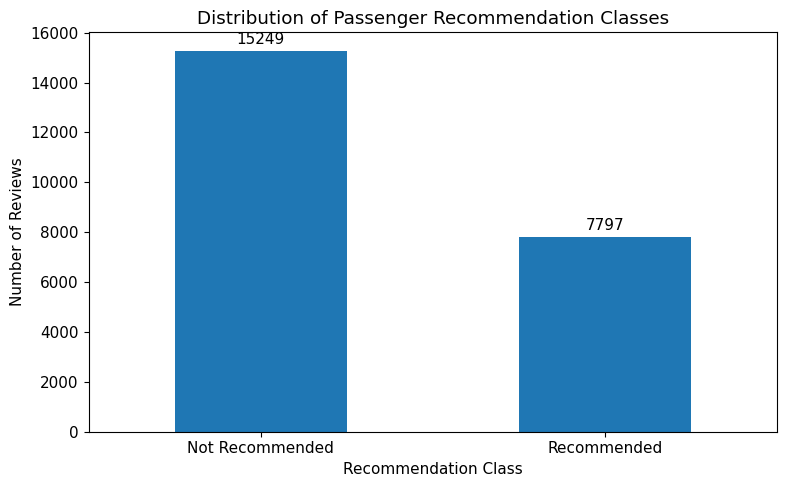


Figure 1 values:
Sentiment_Class
Not Recommended    15249
Recommended         7797
Name: count, dtype: int64


In [92]:
# ============================================================
# FIGURE 1: RECOMMENDATION CLASS DISTRIBUTION
# ============================================================

class_counts = (
    df_clean["Sentiment_Class"]
    .value_counts()
    .reindex(["Not Recommended", "Recommended"])
)

ax = class_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Distribution of Passenger Recommendation Classes")
plt.xlabel("Recommendation Class")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)

# Add exact counts above bars
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.tight_layout()
plt.show()

print("\nFigure 1 values:")
print(class_counts)

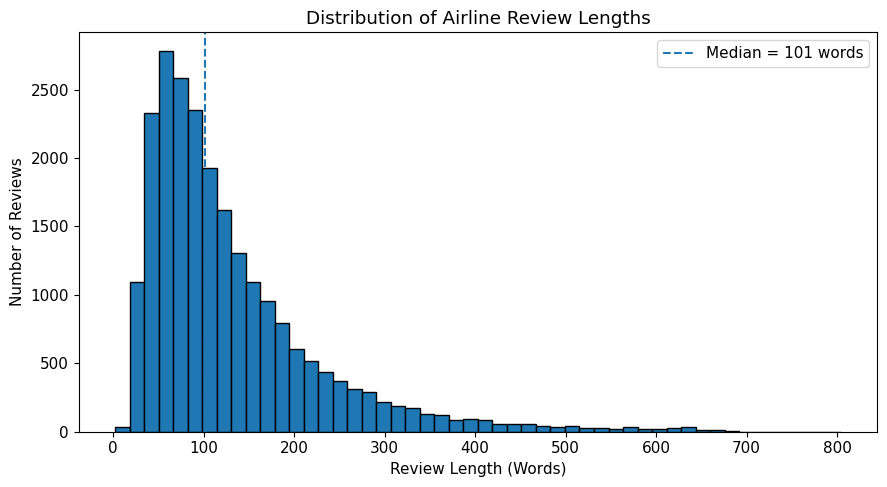

Median review length: 101.0
Mean review length: 130.65


In [93]:
# ============================================================
# FIGURE 2: REVIEW LENGTH DISTRIBUTION
# ============================================================

plt.figure(figsize=(9, 5))

plt.hist(
    df_clean["Review_Length_Words"],
    bins=50,
    edgecolor="black"
)

plt.axvline(
    df_clean["Review_Length_Words"].median(),
    linestyle="--",
    label=f"Median = {df_clean['Review_Length_Words'].median():.0f} words"
)

plt.title("Distribution of Airline Review Lengths")
plt.xlabel("Review Length (Words)")
plt.ylabel("Number of Reviews")
plt.legend()

plt.tight_layout()
plt.show()

print(
    "Median review length:",
    df_clean["Review_Length_Words"].median()
)

print(
    "Mean review length:",
    round(df_clean["Review_Length_Words"].mean(), 2)
)

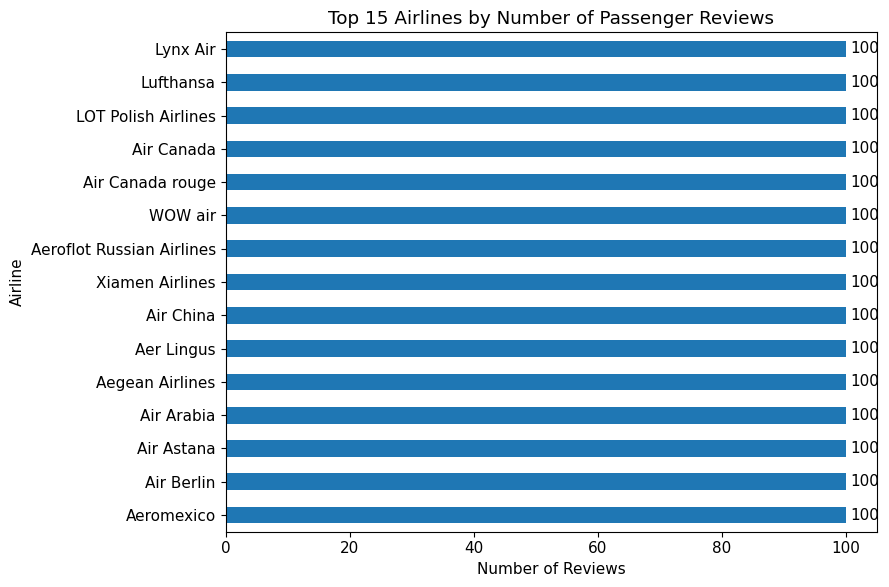


Top 15 airlines:
Airline Name
Aeromexico                   100
Air Berlin                   100
Air Astana                   100
Air Arabia                   100
Aegean Airlines              100
Aer Lingus                   100
Air China                    100
Xiamen Airlines              100
Aeroflot Russian Airlines    100
WOW air                      100
Air Canada rouge             100
Air Canada                   100
LOT Polish Airlines          100
Lufthansa                    100
Lynx Air                     100
Name: count, dtype: int64


In [94]:
# ============================================================
# FIGURE 3: TOP 15 AIRLINES BY REVIEW COUNT
# ============================================================

top_airlines = (
    df_clean["Airline Name"]
    .value_counts()
    .head(15)
    .sort_values()
)

ax = top_airlines.plot(
    kind="barh",
    figsize=(9, 6)
)

plt.title("Top 15 Airlines by Number of Passenger Reviews")
plt.xlabel("Number of Reviews")
plt.ylabel("Airline")

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.tight_layout()
plt.show()

print("\nTop 15 airlines:")
print(
    df_clean["Airline Name"]
    .value_counts()
    .head(15)
)

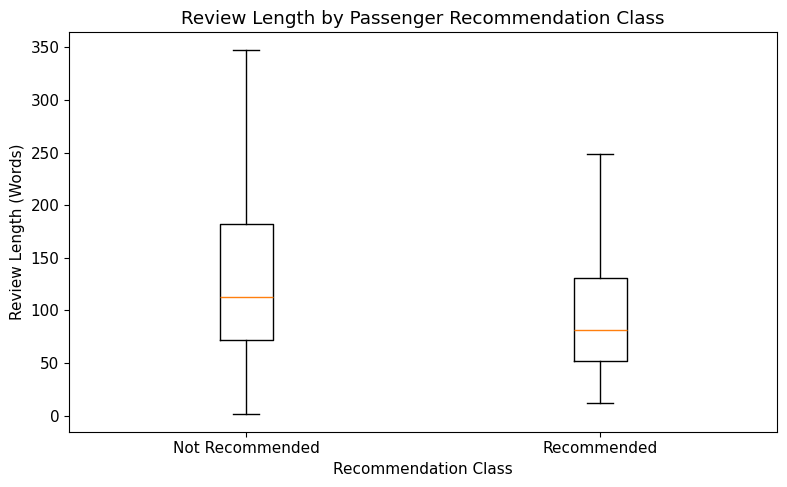


Review length statistics by class:


,Count,Mean,Median,Std_Dev
Sentiment_Class,,,,
Not Recommended,15249,143.76,113.0,105.17
Recommended,7797,105.02,81.0,80.04


In [95]:
# ============================================================
# FIGURE 4: REVIEW LENGTH BY CLASS
# ============================================================

plot_order = [
    "Not Recommended",
    "Recommended"
]

data_to_plot = [
    df_clean.loc[
        df_clean["Sentiment_Class"] == category,
        "Review_Length_Words"
    ]
    for category in plot_order
]

plt.figure(figsize=(8, 5))

plt.boxplot(
    data_to_plot,
    tick_labels=plot_order,
    showfliers=False
)

plt.title("Review Length by Passenger Recommendation Class")
plt.xlabel("Recommendation Class")
plt.ylabel("Review Length (Words)")

plt.tight_layout()
plt.show()

print("\nReview length statistics by class:")

display(
    df_clean.groupby("Sentiment_Class")[
        "Review_Length_Words"
    ].agg(
        Count="count",
        Mean="mean",
        Median="median",
        Std_Dev="std"
    ).round(2)
)

Ratings successfully converted: 22298
Ratings that could not be converted: 748


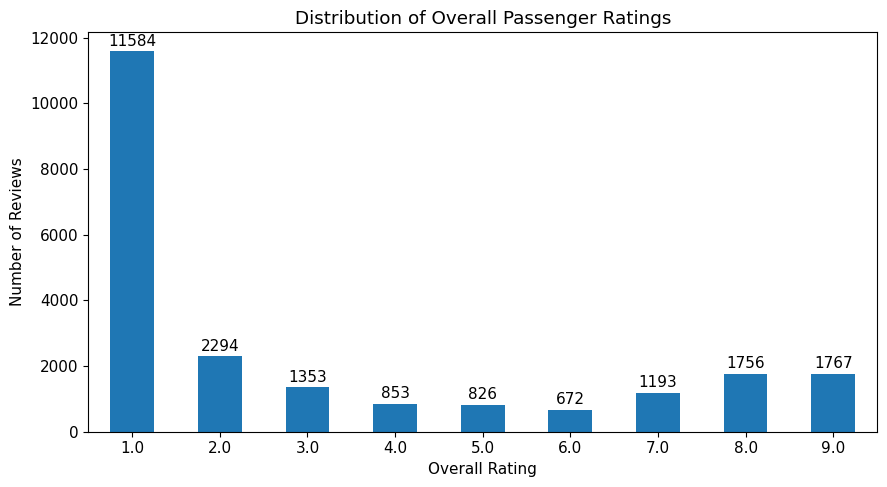


Overall rating distribution:
Overall_Rating_Numeric
1.0    11584
2.0     2294
3.0     1353
4.0      853
5.0      826
6.0      672
7.0     1193
8.0     1756
9.0     1767
Name: count, dtype: int64


In [96]:
# ============================================================
# FIGURE 5: OVERALL RATING DISTRIBUTION
# ============================================================

df_clean["Overall_Rating_Numeric"] = pd.to_numeric(
    df_clean["Overall_Rating"],
    errors="coerce"
)

print(
    "Ratings successfully converted:",
    df_clean["Overall_Rating_Numeric"].notna().sum()
)

print(
    "Ratings that could not be converted:",
    df_clean["Overall_Rating_Numeric"].isna().sum()
)

rating_counts = (
    df_clean["Overall_Rating_Numeric"]
    .value_counts()
    .sort_index()
)

ax = rating_counts.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Distribution of Overall Passenger Ratings")
plt.xlabel("Overall Rating")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=2)

plt.tight_layout()
plt.show()

print("\nOverall rating distribution:")
print(rating_counts)

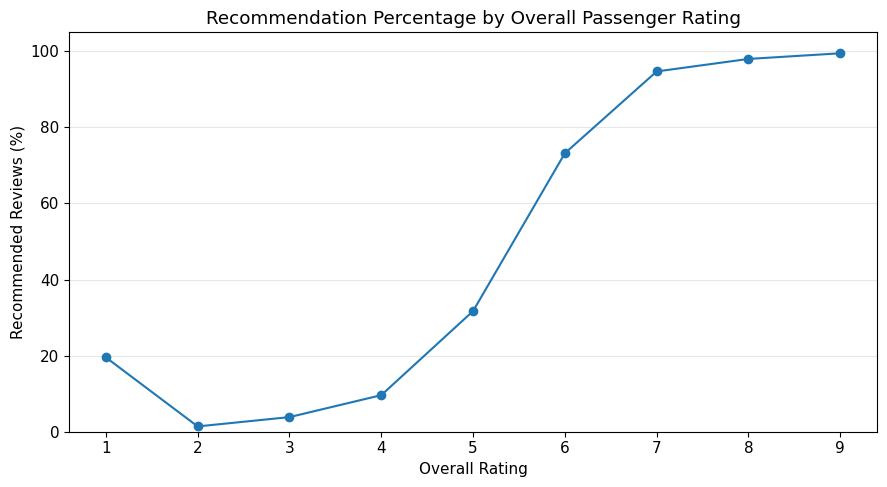


Recommendation percentage by rating:
Overall_Rating_Numeric
1.0    19.54
2.0     1.39
3.0     3.84
4.0     9.61
5.0    31.72
6.0    73.21
7.0    94.72
8.0    98.01
9.0    99.49
Name: Sentiment_Label, dtype: float64


In [97]:
# ============================================================
# FIGURE 6: RECOMMENDATION PERCENTAGE BY OVERALL RATING
# ============================================================

rating_recommendation = (
    df_clean
    .dropna(subset=["Overall_Rating_Numeric"])
    .groupby("Overall_Rating_Numeric")[
        "Sentiment_Label"
    ]
    .mean()
    .mul(100)
)

plt.figure(figsize=(9, 5))

plt.plot(
    rating_recommendation.index,
    rating_recommendation.values,
    marker="o"
)

plt.title("Recommendation Percentage by Overall Passenger Rating")
plt.xlabel("Overall Rating")
plt.ylabel("Recommended Reviews (%)")
plt.ylim(0, 105)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print("\nRecommendation percentage by rating:")
print(rating_recommendation.round(2))

In [98]:
# ============================================================
# STEP 4A: NLTK SETUP
# ============================================================

import nltk
import re
import time
import pandas as pd

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

# Download required resources
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

print("=" * 70)
print("NLTK SETUP COMPLETE")
print("=" * 70)

print(f"Number of English stop words: {len(stop_words)}")
print("WordNet lemmatizer ready.")

NLTK SETUP COMPLETE
Number of English stop words: 198
WordNet lemmatizer ready.


In [99]:
# ============================================================
# STEP 4B: NLTK PREPROCESSING FUNCTION
# ============================================================

def preprocess_nltk(text):
    """
    Clean airline review text using NLTK.

    Steps:
    1. Convert text to lowercase
    2. Remove URLs
    3. Remove non-alphabetic characters
    4. Tokenise
    5. Remove English stop words
    6. Remove one-character tokens
    7. Apply WordNet lemmatisation
    """

    # Convert to lowercase
    text = str(text).lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", " ", text)

    # Keep alphabetic characters and spaces
    text = re.sub(r"[^a-z\s]", " ", text)

    # Remove repeated whitespace
    text = re.sub(r"\s+", " ", text).strip()

    # Tokenisation
    tokens = word_tokenize(text)

    # Stop-word removal and basic filtering
    filtered_tokens = [
        token
        for token in tokens
        if token not in stop_words
        and len(token) > 1
    ]

    # Lemmatise tokens
    lemmas = [
        lemmatizer.lemmatize(token)
        for token in filtered_tokens
    ]

    return " ".join(lemmas)

In [100]:
# ============================================================
# TEST NLTK PREPROCESSING ON ONE REAL REVIEW
# ============================================================

sample_review = df_clean["Review"].iloc[1]

print("=" * 70)
print("ORIGINAL REVIEW")
print("=" * 70)
print(sample_review)

print("\n" + "=" * 70)
print("NLTK CLEANED REVIEW")
print("=" * 70)
print(preprocess_nltk(sample_review))

ORIGINAL REVIEW
Moroni to Anjouan. It is a very small airline. My ticket advised me to turn up at 0800hrs which I did. There was confusion at this small airport. I was then directed to the office of AB Aviation which was still closed. It opened at 0900hrs and I was told that the flight had been put back to 1300hrs and that they had tried to contact me. This could not be true as they did not have my phone number. I was with a local guide and he had not been informed either. I presume that I was bumped off. The later flight did operate but as usual, there was confusion at check-in. The flight was only 30mins and there were no further problems. Not a good airline but it is the only one for Comoros.

NLTK CLEANED REVIEW
moroni anjouan small airline ticket advised turn hr confusion small airport directed office ab aviation still closed opened hr told flight put back hr tried contact could true phone number local guide informed either presume bumped later flight operate usual confusion check

In [101]:
# ============================================================
# STEP 4C: APPLY NLTK PREPROCESSING
# ============================================================

print("=" * 70)
print("APPLYING NLTK PREPROCESSING")
print("=" * 70)

start_time = time.time()

df_clean["NLTK_Cleaned"] = (
    df_clean["Review"]
    .apply(preprocess_nltk)
)

nltk_time = time.time() - start_time

print("\nNLTK preprocessing completed successfully.")

print(
    f"Processing time: "
    f"{nltk_time:.2f} seconds"
)

print(
    f"Empty processed reviews: "
    f"{(df_clean['NLTK_Cleaned'].str.len() == 0).sum():,}"
)

APPLYING NLTK PREPROCESSING

NLTK preprocessing completed successfully.
Processing time: 44.12 seconds
Empty processed reviews: 0


In [102]:
# ============================================================
# STEP 4D: NLTK OUTPUT STATISTICS
# ============================================================

df_clean["NLTK_Token_Count"] = (
    df_clean["NLTK_Cleaned"]
    .str.split()
    .str.len()
)

# Build vocabulary
nltk_vocabulary = set()

for text in df_clean["NLTK_Cleaned"]:
    nltk_vocabulary.update(text.split())

total_nltk_tokens = df_clean["NLTK_Token_Count"].sum()
nltk_vocab_size = len(nltk_vocabulary)

print("=" * 70)
print("NLTK PREPROCESSING SUMMARY")
print("=" * 70)

print(f"Reviews processed: {len(df_clean):,}")
print(f"Total cleaned tokens: {total_nltk_tokens:,}")
print(f"Unique vocabulary size: {nltk_vocab_size:,}")

print(
    f"Average cleaned tokens per review: "
    f"{df_clean['NLTK_Token_Count'].mean():.2f}"
)

print(
    f"Median cleaned tokens per review: "
    f"{df_clean['NLTK_Token_Count'].median():.0f}"
)

print(
    f"Processing time: "
    f"{nltk_time:.2f} seconds"
)

NLTK PREPROCESSING SUMMARY
Reviews processed: 23,046
Total cleaned tokens: 1,508,038
Unique vocabulary size: 26,797
Average cleaned tokens per review: 65.44
Median cleaned tokens per review: 51
Processing time: 44.12 seconds


In [103]:
# ============================================================
# STEP 4E: ORIGINAL VS NLTK OUTPUT
# ============================================================

comparison_nltk = df_clean[
    [
        "Review",
        "NLTK_Cleaned",
        "NLTK_Token_Count"
    ]
].head(5).copy()

display(comparison_nltk)

,Review,NLTK_Cleaned,NLTK_Token_Count
0,"Moroni to Moheli. Turned out to be a pretty decent airline. Online booking worked well, checkin and boarding was fine and the plane looked well maintained. Its a very short fli...",moroni moheli turned pretty decent airline online booking worked well checkin boarding fine plane looked well maintained short flight minute expect much still managed hand bott...,32
1,Moroni to Anjouan. It is a very small airline. My ticket advised me to turn up at 0800hrs which I did. There was confusion at this small airport. I was then directed to the off...,moroni anjouan small airline ticket advised turn hr confusion small airport directed office ab aviation still closed opened hr told flight put back hr tried contact could true ...,49
2,Anjouan to Dzaoudzi. A very small airline and the only airline based in Comoros. Check-in was disorganised because of locals with big packages and disinterested staff. The flig...,anjouan dzaoudzi small airline airline based comoros check disorganised local big package disinterested staff flight fortunately short min took time landed time short flight li...,36
3,"Please do a favor yourself and do not fly with Adria. On the route from Munich to Pristina in July 2019 they lost my luggage and for 10 days in a row, despite numerous phone ca...",please favor fly adria route munich pristina july lost luggage day row despite numerous phone call able locate day later luggage arrived destination completely ruined applying ...,62
4,"Do not book a flight with this airline! My friend and I should have returned from Sofia to Amsterdam on September 22 and 3 days before, they sent us an SMS informing the flight...",book flight airline friend returned sofia amsterdam september day sent u sm informing flight cancelled straight day tried reach airline web agent dream get solution finally hou...,52


In [104]:
# ============================================================
# STEP 5A: SPACY SETUP
# ============================================================

!pip -q install -U spacy

import spacy
import time
import pandas as pd
from collections import Counter

# Download English model only if unavailable
try:
    nlp = spacy.load("en_core_web_sm")
except OSError:
    !python -m spacy download en_core_web_sm -q
    nlp = spacy.load("en_core_web_sm")

print("=" * 70)
print("SPACY SETUP COMPLETE")
print("=" * 70)

print("spaCy version:", spacy.__version__)
print("Model:", "en_core_web_sm")
print("Pipeline components:", nlp.pipe_names)

SPACY SETUP COMPLETE
spaCy version: 3.8.18
Model: en_core_web_sm
Pipeline components: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']


In [105]:
# ============================================================
# STEP 5B: TEST SPACY ON SAME REVIEW
# ============================================================

sample_review = df_clean["Review"].iloc[1]

doc = nlp(sample_review)

# Lemmatise and remove stop words/punctuation
spacy_tokens = [
    token.lemma_.lower()
    for token in doc
    if token.is_alpha
    and not token.is_stop
    and len(token.lemma_) > 1
]

spacy_cleaned_sample = " ".join(spacy_tokens)

print("=" * 70)
print("ORIGINAL REVIEW")
print("=" * 70)
print(sample_review)

print("\n" + "=" * 70)
print("NLTK CLEANED")
print("=" * 70)
print(df_clean["NLTK_Cleaned"].iloc[1])

print("\n" + "=" * 70)
print("SPACY CLEANED")
print("=" * 70)
print(spacy_cleaned_sample)

print("\n" + "=" * 70)
print("NAMED ENTITIES DETECTED")
print("=" * 70)

if len(doc.ents) > 0:
    for ent in doc.ents:
        print(
            f"{ent.text:<30} "
            f"{ent.label_:<12} "
            f"{spacy.explain(ent.label_)}"
        )
else:
    print("No named entities detected.")

ORIGINAL REVIEW
Moroni to Anjouan. It is a very small airline. My ticket advised me to turn up at 0800hrs which I did. There was confusion at this small airport. I was then directed to the office of AB Aviation which was still closed. It opened at 0900hrs and I was told that the flight had been put back to 1300hrs and that they had tried to contact me. This could not be true as they did not have my phone number. I was with a local guide and he had not been informed either. I presume that I was bumped off. The later flight did operate but as usual, there was confusion at check-in. The flight was only 30mins and there were no further problems. Not a good airline but it is the only one for Comoros.

NLTK CLEANED
moroni anjouan small airline ticket advised turn hr confusion small airport directed office ab aviation still closed opened hr told flight put back hr tried contact could true phone number local guide informed either presume bumped later flight operate usual confusion check flight

In [106]:
# ============================================================
# STEP 5C: BATCH SPACY PREPROCESSING + NER
# ============================================================

print("=" * 70)
print("SPACY BATCH PROCESSING")
print("=" * 70)

reviews = df_clean["Review"].tolist()

spacy_cleaned_reviews = []
spacy_token_counts = []
all_entities = []
entity_counts_per_review = []

start_time = time.time()

# nlp.pipe is considerably more efficient than repeatedly calling nlp()
for doc in nlp.pipe(
    reviews,
    batch_size=64
):

    # --------------------------------------------------------
    # Cleaned / lemmatised text
    # --------------------------------------------------------

    tokens = [
        token.lemma_.lower()
        for token in doc
        if token.is_alpha
        and not token.is_stop
        and len(token.lemma_) > 1
    ]

    cleaned_text = " ".join(tokens)

    spacy_cleaned_reviews.append(cleaned_text)
    spacy_token_counts.append(len(tokens))

    # --------------------------------------------------------
    # Named entities
    # --------------------------------------------------------

    review_entities = []

    for ent in doc.ents:

        # Keep useful entity types for customer feedback
        if ent.label_ in {
            "ORG",
            "GPE",
            "LOC",
            "DATE",
            "TIME",
            "MONEY",
            "PRODUCT",
            "FAC"
        }:
            review_entities.append(
                (ent.text, ent.label_)
            )

            all_entities.append(
                (ent.text, ent.label_)
            )

    entity_counts_per_review.append(
        len(review_entities)
    )

spacy_time = time.time() - start_time

# Store results
df_clean["spaCy_Cleaned"] = spacy_cleaned_reviews
df_clean["spaCy_Token_Count"] = spacy_token_counts
df_clean["NER_Count"] = entity_counts_per_review

print("\nspaCy processing completed successfully.")

print(
    f"Processing time: "
    f"{spacy_time:.2f} seconds"
)

print(
    f"Reviews processed: "
    f"{len(spacy_cleaned_reviews):,}"
)

print(
    f"Empty processed reviews: "
    f"{(df_clean['spaCy_Cleaned'].str.len() == 0).sum():,}"
)

print(
    f"Total retained named entities: "
    f"{len(all_entities):,}"
)

SPACY BATCH PROCESSING

spaCy processing completed successfully.
Processing time: 444.30 seconds
Reviews processed: 23,046
Empty processed reviews: 0
Total retained named entities: 132,217


In [107]:
# ============================================================
# STEP 5D: SPACY PREPROCESSING STATISTICS
# ============================================================

spacy_vocabulary = set()

for text in df_clean["spaCy_Cleaned"]:
    spacy_vocabulary.update(text.split())

total_spacy_tokens = df_clean["spaCy_Token_Count"].sum()
spacy_vocab_size = len(spacy_vocabulary)

print("=" * 70)
print("SPACY PREPROCESSING SUMMARY")
print("=" * 70)

print(f"Reviews processed: {len(df_clean):,}")
print(f"Total cleaned tokens: {total_spacy_tokens:,}")
print(f"Unique vocabulary size: {spacy_vocab_size:,}")

print(
    f"Average cleaned tokens per review: "
    f"{df_clean['spaCy_Token_Count'].mean():.2f}"
)

print(
    f"Median cleaned tokens per review: "
    f"{df_clean['spaCy_Token_Count'].median():.0f}"
)

print(
    f"Processing time: "
    f"{spacy_time:.2f} seconds"
)

print(
    f"Total retained named entities: "
    f"{len(all_entities):,}"
)

SPACY PREPROCESSING SUMMARY
Reviews processed: 23,046
Total cleaned tokens: 1,310,531
Unique vocabulary size: 24,830
Average cleaned tokens per review: 56.87
Median cleaned tokens per review: 45
Processing time: 444.30 seconds
Total retained named entities: 132,217


In [108]:
# ============================================================
# STEP 5E: NAMED ENTITY ANALYSIS
# ============================================================

entity_type_counts = Counter(
    label
    for text, label in all_entities
)

print("=" * 70)
print("ENTITY TYPE FREQUENCIES")
print("=" * 70)

entity_type_df = pd.DataFrame(
    entity_type_counts.items(),
    columns=[
        "Entity_Type",
        "Frequency"
    ]
).sort_values(
    "Frequency",
    ascending=False
)

display(entity_type_df)

print("\n" + "=" * 70)
print("TOP 20 ENTITY TEXTS")
print("=" * 70)

entity_text_counts = Counter(
    text.strip()
    for text, label in all_entities
    if text.strip()
)

top_entities_df = pd.DataFrame(
    entity_text_counts.most_common(20),
    columns=[
        "Entity",
        "Frequency"
    ]
)

display(top_entities_df)

ENTITY TYPE FREQUENCIES


,Entity_Type,Frequency
0,GPE,44310
3,ORG,35305
1,TIME,22265
2,DATE,19285
6,MONEY,3960
4,PRODUCT,2667
5,LOC,2397
7,FAC,2028



TOP 20 ENTITY TEXTS


,Entity,Frequency
0,London,1059
1,Bangkok,992
2,Paris,927
3,Singapore,815
4,2 hours,774
5,Toronto,721
6,the next day,635
7,Dubai,582
8,Sydney,580
9,3 hours,567


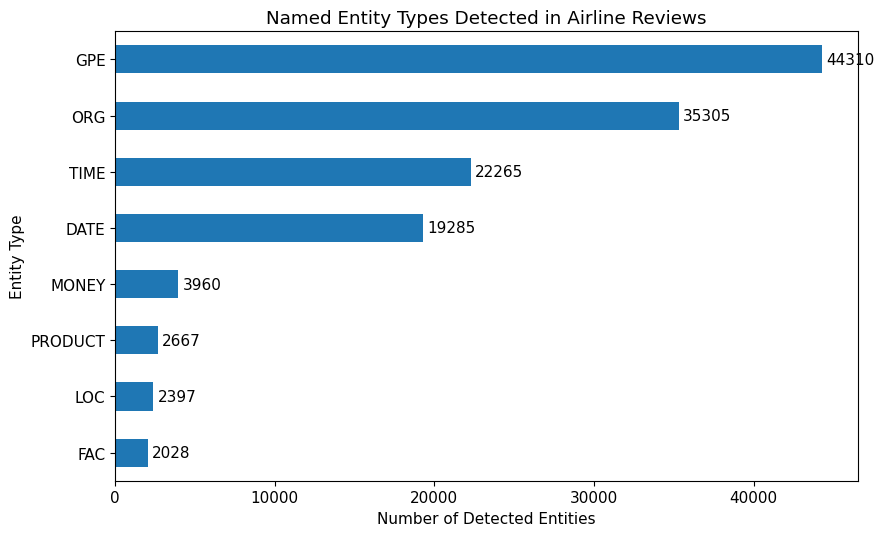

In [109]:
# ============================================================
# FIGURE 7: NAMED ENTITY TYPE FREQUENCIES
# ============================================================

entity_plot = (
    entity_type_df
    .sort_values(
        "Frequency",
        ascending=True
    )
)

ax = entity_plot.plot(
    x="Entity_Type",
    y="Frequency",
    kind="barh",
    figsize=(9, 5.5),
    legend=False
)

plt.title("Named Entity Types Detected in Airline Reviews")
plt.xlabel("Number of Detected Entities")
plt.ylabel("Entity Type")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%d",
        padding=3
    )

plt.tight_layout()
plt.show()

In [110]:
# ============================================================
# NLTK VS SPACY SAMPLE OUTPUT
# ============================================================

comparison = df_clean[
    [
        "Review",
        "NLTK_Cleaned",
        "spaCy_Cleaned",
        "NLTK_Token_Count",
        "spaCy_Token_Count",
        "NER_Count"
    ]
].head(5)

display(comparison)

,Review,NLTK_Cleaned,spaCy_Cleaned,NLTK_Token_Count,spaCy_Token_Count,NER_Count
0,"Moroni to Moheli. Turned out to be a pretty decent airline. Online booking worked well, checkin and boarding was fine and the plane looked well maintained. Its a very short fli...",moroni moheli turned pretty decent airline online booking worked well checkin boarding fine plane looked well maintained short flight minute expect much still managed hand bott...,moroni moheli turn pretty decent airline online booking work checkin boarding fine plane look maintain short flight minute expect manage hand bottle water biscuit nice flight time,32,27,2
1,Moroni to Anjouan. It is a very small airline. My ticket advised me to turn up at 0800hrs which I did. There was confusion at this small airport. I was then directed to the off...,moroni anjouan small airline ticket advised turn hr confusion small airport directed office ab aviation still closed opened hr told flight put back hr tried contact could true ...,moroni anjouan small airline ticket advise turn confusion small airport direct office ab aviation closed open tell flight try contact true phone number local guide inform presu...,49,39,3
2,Anjouan to Dzaoudzi. A very small airline and the only airline based in Comoros. Check-in was disorganised because of locals with big packages and disinterested staff. The flig...,anjouan dzaoudzi small airline airline based comoros check disorganised local big package disinterested staff flight fortunately short min took time landed time short flight li...,anjouan dzaoudzi small airline airline base comoros check disorganise local big package disinterested staff flight fortunately short min take time land time short flight like c...,36,34,1
3,"Please do a favor yourself and do not fly with Adria. On the route from Munich to Pristina in July 2019 they lost my luggage and for 10 days in a row, despite numerous phone ca...",please favor fly adria route munich pristina july lost luggage day row despite numerous phone call able locate day later luggage arrived destination completely ruined applying ...,favor fly adria route munich pristina july lose luggage day row despite numerous phone call able locate day later luggage arrive destination completely ruin apply compensation ...,62,57,10
4,"Do not book a flight with this airline! My friend and I should have returned from Sofia to Amsterdam on September 22 and 3 days before, they sent us an SMS informing the flight...",book flight airline friend returned sofia amsterdam september day sent u sm informing flight cancelled straight day tried reach airline web agent dream get solution finally hou...,book flight airline friend return sofia amsterdam september day send sms inform flight cancel straight day try reach airline web agent dream solution finally hour cancel flight...,52,45,11


In [111]:
# ============================================================
# STEP 6A: NLTK VS SPACY COMPARISON TABLE
# ============================================================

comparison_table = pd.DataFrame({
    "Measure": [
        "Reviews processed",
        "Total cleaned tokens",
        "Vocabulary size",
        "Average tokens per review",
        "Median tokens per review",
        "Processing time (seconds)",
        "Named entity recognition",
        "Example: advised",
        "Example: informed",
        "Example: bumped"
    ],

    "NLTK": [
        f"{len(df_clean):,}",
        f"{total_nltk_tokens:,}",
        f"{nltk_vocab_size:,}",
        f"{df_clean['NLTK_Token_Count'].mean():.2f}",
        f"{df_clean['NLTK_Token_Count'].median():.0f}",
        f"{nltk_time:.2f}",
        "Not used",
        "advised",
        "informed",
        "bumped"
    ],

    "spaCy": [
        f"{len(df_clean):,}",
        f"{total_spacy_tokens:,}",
        f"{spacy_vocab_size:,}",
        f"{df_clean['spaCy_Token_Count'].mean():.2f}",
        f"{df_clean['spaCy_Token_Count'].median():.0f}",
        f"{spacy_time:.2f}",
        f"{len(all_entities):,} retained entities",
        "advise",
        "inform",
        "bump"
    ],

    "Practical_Interpretation": [
        "Both methods process the complete cleaned dataset.",
        "spaCy produces fewer retained tokens after linguistic processing.",
        "spaCy creates a smaller normalised vocabulary.",
        "spaCy retains fewer tokens per customer review.",
        "Both methods substantially reduce raw review length.",
        "NLTK is substantially faster for this implementation.",
        "spaCy provides contextual entity extraction.",
        "spaCy provides stronger verb normalisation.",
        "spaCy provides stronger verb normalisation.",
        "spaCy provides stronger verb normalisation."
    ]
})

print("=" * 70)
print("NLTK VS SPACY COMPARISON")
print("=" * 70)

display(comparison_table)

NLTK VS SPACY COMPARISON


,Measure,NLTK,spaCy,Practical_Interpretation
0,Reviews processed,"23,046","23,046",Both methods process the complete cleaned dataset.
1,Total cleaned tokens,"1,508,038","1,310,531",spaCy produces fewer retained tokens after linguistic processing.
2,Vocabulary size,"26,797","24,830",spaCy creates a smaller normalised vocabulary.
3,Average tokens per review,65.44,56.87,spaCy retains fewer tokens per customer review.
4,Median tokens per review,51,45,Both methods substantially reduce raw review length.
5,Processing time (seconds),44.12,444.30,NLTK is substantially faster for this implementation.
6,Named entity recognition,Not used,"132,217 retained entities",spaCy provides contextual entity extraction.
7,Example: advised,advised,advise,spaCy provides stronger verb normalisation.
8,Example: informed,informed,inform,spaCy provides stronger verb normalisation.
9,Example: bumped,bumped,bump,spaCy provides stronger verb normalisation.


In [112]:
# ============================================================
# STEP 6B: MOST FREQUENT CLEANED TERMS
# ============================================================

from collections import Counter

all_spacy_words = []

for text in df_clean["spaCy_Cleaned"]:
    all_spacy_words.extend(text.split())

word_frequencies = Counter(all_spacy_words)

top_20_words = pd.DataFrame(
    word_frequencies.most_common(20),
    columns=["Term", "Frequency"]
)

print("=" * 70)
print("TOP 20 CLEANED TERMS")
print("=" * 70)

display(top_20_words)

TOP 20 CLEANED TERMS


,Term,Frequency
0,flight,50489
1,airline,15802
2,time,15274
3,seat,13881
4,service,13614
5,hour,12990
6,fly,12394
7,check,11249
8,airport,8752
9,delay,8624


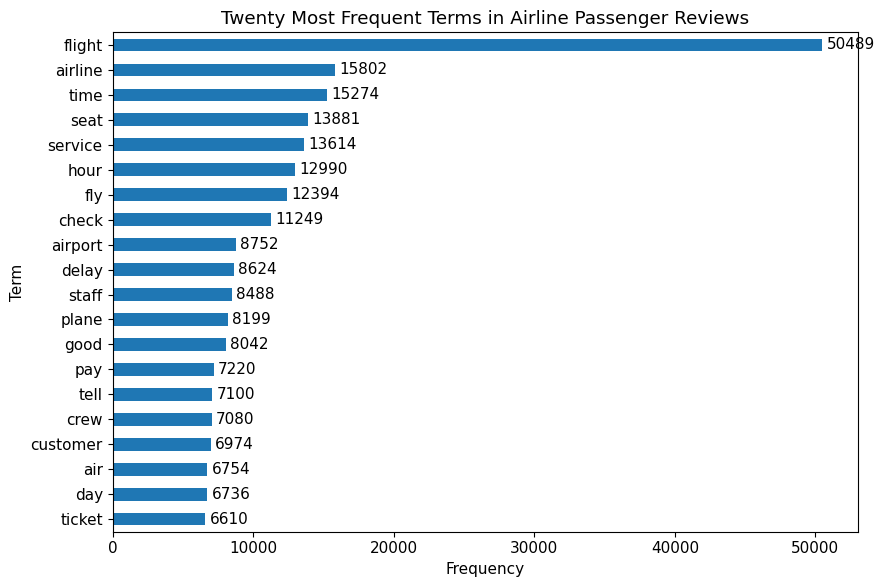

In [113]:
# ============================================================
# FIGURE 8: TOP 20 CLEANED TERMS
# ============================================================

plot_words = top_20_words.sort_values(
    "Frequency",
    ascending=True
)

ax = plot_words.plot(
    x="Term",
    y="Frequency",
    kind="barh",
    figsize=(9, 6),
    legend=False
)

plt.title("Twenty Most Frequent Terms in Airline Passenger Reviews")
plt.xlabel("Frequency")
plt.ylabel("Term")

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.tight_layout()
plt.show()

In [114]:
# ============================================================
# STEP 6C: CLASS-SPECIFIC WORD FREQUENCIES
# ============================================================

negative_words = " ".join(
    df_clean.loc[
        df_clean["Sentiment_Label"] == 0,
        "spaCy_Cleaned"
    ]
).split()

positive_words = " ".join(
    df_clean.loc[
        df_clean["Sentiment_Label"] == 1,
        "spaCy_Cleaned"
    ]
).split()

negative_frequency = Counter(negative_words)
positive_frequency = Counter(positive_words)

top_negative = pd.DataFrame(
    negative_frequency.most_common(20),
    columns=["Term", "Frequency"]
)

top_positive = pd.DataFrame(
    positive_frequency.most_common(20),
    columns=["Term", "Frequency"]
)

print("=" * 70)
print("TOP TERMS — NOT RECOMMENDED")
print("=" * 70)

display(top_negative)

print("\n" + "=" * 70)
print("TOP TERMS — RECOMMENDED")
print("=" * 70)

display(top_positive)

TOP TERMS — NOT RECOMMENDED


,Term,Frequency
0,flight,35537
1,airline,12148
2,hour,10764
3,time,10050
4,service,8936
5,fly,8591
6,seat,8426
7,check,7793
8,delay,7238
9,airport,6796



TOP TERMS — RECOMMENDED


,Term,Frequency
0,flight,14952
1,good,5482
2,seat,5455
3,time,5224
4,service,4678
5,crew,3941
6,fly,3803
7,airline,3654
8,check,3456
9,food,3101


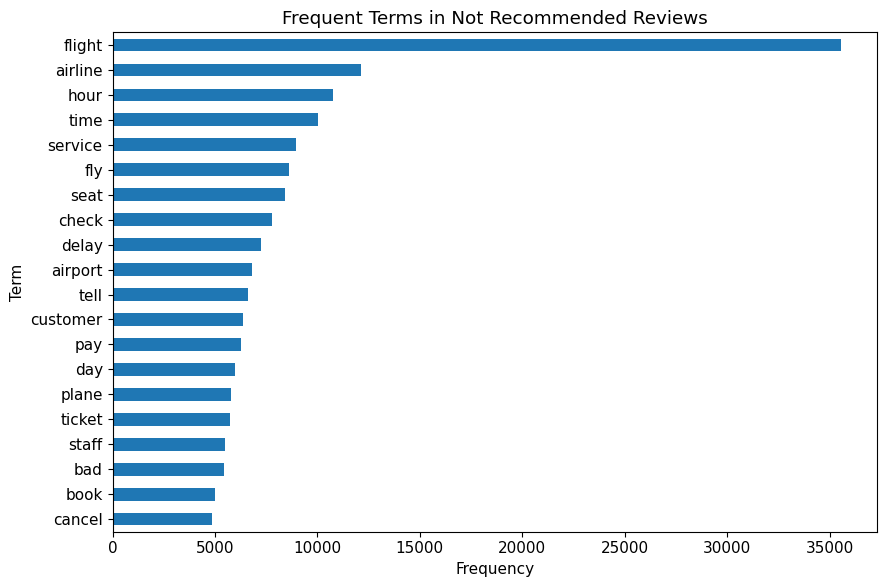

In [115]:
# ============================================================
# FIGURE 9: FREQUENT TERMS — NOT RECOMMENDED
# ============================================================

plot_negative = top_negative.sort_values(
    "Frequency",
    ascending=True
)

ax = plot_negative.plot(
    x="Term",
    y="Frequency",
    kind="barh",
    figsize=(9, 6),
    legend=False
)

plt.title("Frequent Terms in Not Recommended Reviews")
plt.xlabel("Frequency")
plt.ylabel("Term")

plt.tight_layout()
plt.show()

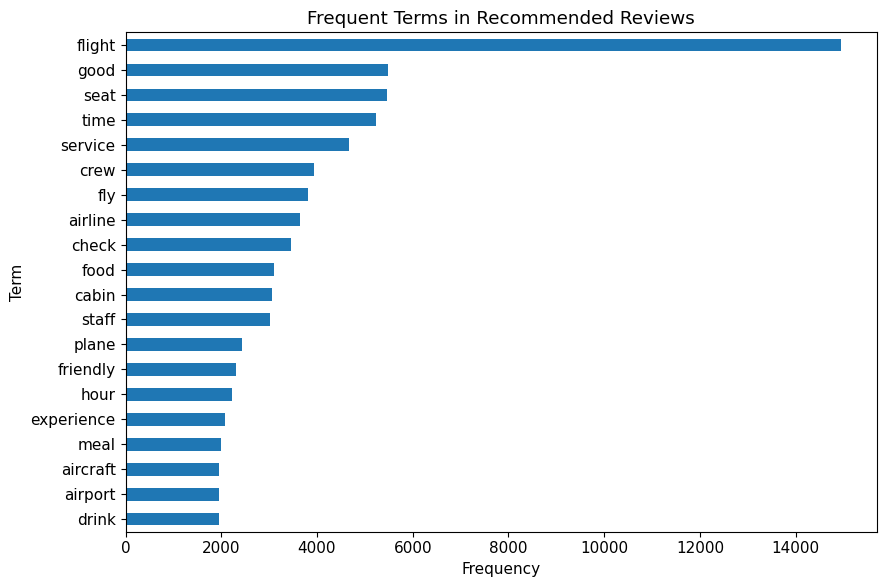

In [116]:
# ============================================================
# FIGURE 10: FREQUENT TERMS — RECOMMENDED
# ============================================================

plot_positive = top_positive.sort_values(
    "Frequency",
    ascending=True
)

ax = plot_positive.plot(
    x="Term",
    y="Frequency",
    kind="barh",
    figsize=(9, 6),
    legend=False
)

plt.title("Frequent Terms in Recommended Reviews")
plt.xlabel("Frequency")
plt.ylabel("Term")

plt.tight_layout()
plt.show()

In [117]:
# ============================================================
# STEP 6E: WORD CLOUDS
# ============================================================

!pip -q install wordcloud

from wordcloud import WordCloud
import matplotlib.pyplot as plt

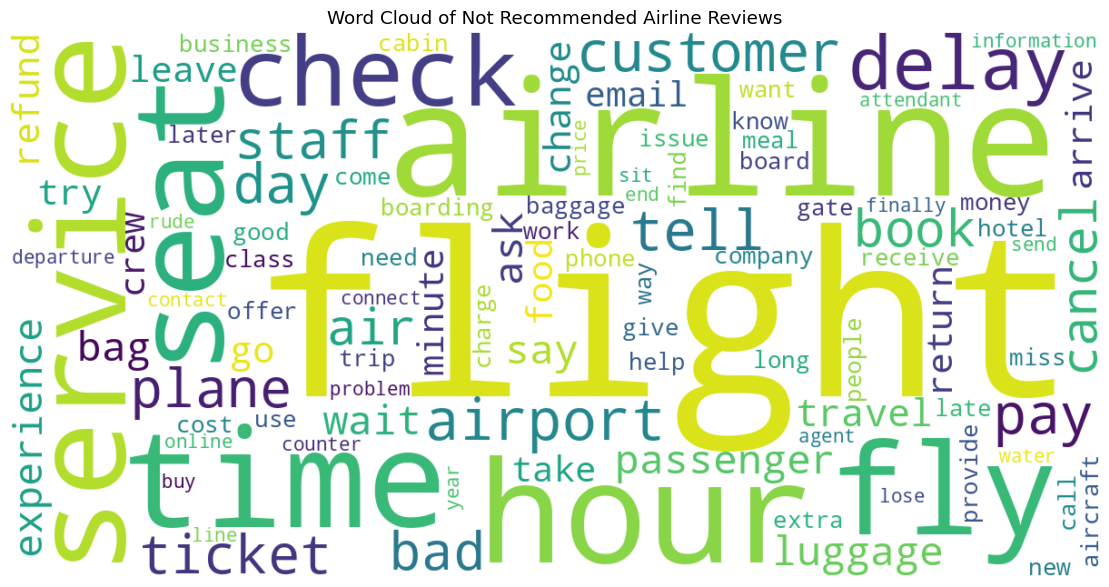

In [118]:
negative_text = " ".join(
    df_clean.loc[
        df_clean["Sentiment_Label"] == 0,
        "spaCy_Cleaned"
    ]
)

negative_cloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    max_words=100,
    collocations=False
).generate(negative_text)

plt.figure(figsize=(12, 6))
plt.imshow(negative_cloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Not Recommended Airline Reviews")
plt.tight_layout()
plt.show()

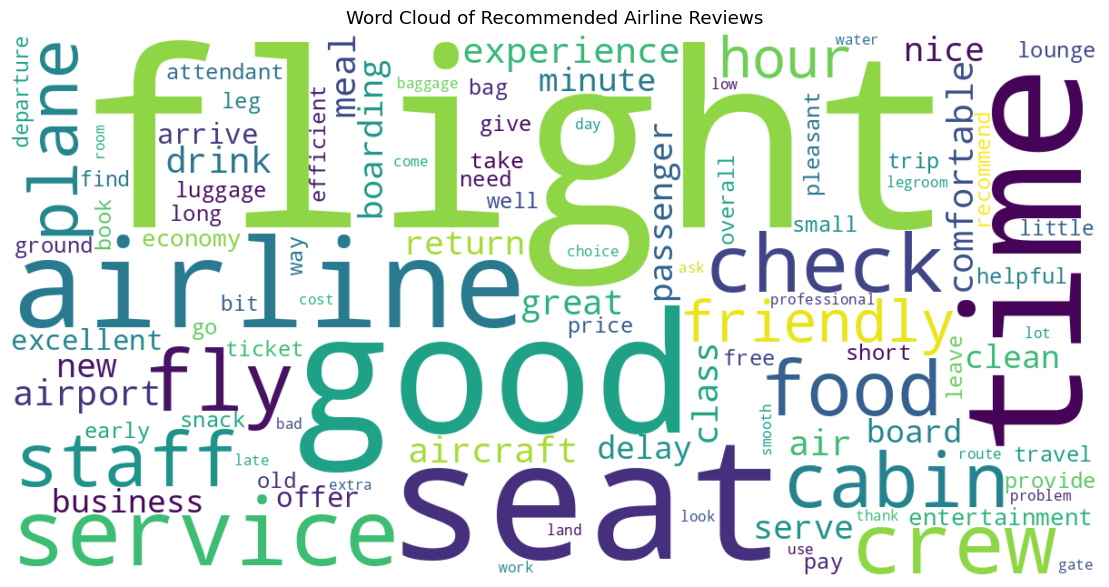

In [119]:
positive_text = " ".join(
    df_clean.loc[
        df_clean["Sentiment_Label"] == 1,
        "spaCy_Cleaned"
    ]
)

positive_cloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    max_words=100,
    collocations=False
).generate(positive_text)

plt.figure(figsize=(12, 6))
plt.imshow(positive_cloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Recommended Airline Reviews")
plt.tight_layout()
plt.show()

In [120]:
# ============================================================
# STEP 7A: STRATIFIED TRAIN / TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np

X = df_clean["spaCy_Cleaned"]
y = df_clean["Sentiment_Label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("=" * 70)
print("STRATIFIED TRAIN / TEST SPLIT")
print("=" * 70)

print(f"Complete dataset: {len(X):,}")
print(f"Training reviews: {len(X_train):,}")
print(f"Testing reviews: {len(X_test):,}")

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTraining percentages:")
print(
    y_train.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nTesting class distribution:")
print(y_test.value_counts())

print("\nTesting percentages:")
print(
    y_test.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

STRATIFIED TRAIN / TEST SPLIT
Complete dataset: 23,046
Training reviews: 18,436
Testing reviews: 4,610

Training class distribution:
Sentiment_Label
0    12199
1     6237
Name: count, dtype: int64

Training percentages:
Sentiment_Label
0    66.17
1    33.83
Name: proportion, dtype: float64

Testing class distribution:
Sentiment_Label
0    3050
1    1560
Name: count, dtype: int64

Testing percentages:
Sentiment_Label
0    66.16
1    33.84
Name: proportion, dtype: float64


In [121]:
# ============================================================
# STEP 7B: TF-IDF FEATURE EXTRACTION
# ============================================================

from sklearn.feature_extraction.text import TfidfVectorizer
import time

tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.95,
    max_features=30000,
    sublinear_tf=True
)

print("=" * 70)
print("TF-IDF FEATURE EXTRACTION")
print("=" * 70)

start_time = time.time()

# FIT only on training data
X_train_tfidf = tfidf.fit_transform(X_train)

# TRANSFORM test data using training vocabulary
X_test_tfidf = tfidf.transform(X_test)

tfidf_time = time.time() - start_time

print(f"Training matrix shape: {X_train_tfidf.shape}")
print(f"Testing matrix shape: {X_test_tfidf.shape}")
print(f"TF-IDF vocabulary size: {len(tfidf.vocabulary_):,}")

print(
    f"Feature extraction time: "
    f"{tfidf_time:.2f} seconds"
)

print(
    f"Training matrix type: "
    f"{type(X_train_tfidf)}"
)

TF-IDF FEATURE EXTRACTION
Training matrix shape: (18436, 30000)
Testing matrix shape: (4610, 30000)
TF-IDF vocabulary size: 30,000
Feature extraction time: 11.33 seconds
Training matrix type: <class 'scipy.sparse._csr.csr_matrix'>


In [122]:
# ============================================================
# STEP 7C: LOGISTIC REGRESSION BASELINE
# ============================================================

from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

print("=" * 70)
print("TRAINING LOGISTIC REGRESSION")
print("=" * 70)

start_time = time.time()

logistic_model.fit(
    X_train_tfidf,
    y_train
)

logistic_training_time = time.time() - start_time

print("Training completed successfully.")

print(
    f"Training time: "
    f"{logistic_training_time:.2f} seconds"
)

TRAINING LOGISTIC REGRESSION
Training completed successfully.
Training time: 1.29 seconds


In [123]:
# ============================================================
# STEP 7D: LOGISTIC REGRESSION EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

y_pred_lr = logistic_model.predict(
    X_test_tfidf
)

lr_accuracy = accuracy_score(
    y_test,
    y_pred_lr
)

lr_precision = precision_score(
    y_test,
    y_pred_lr,
    average="weighted"
)

lr_recall = recall_score(
    y_test,
    y_pred_lr,
    average="weighted"
)

lr_f1_weighted = f1_score(
    y_test,
    y_pred_lr,
    average="weighted"
)

lr_f1_macro = f1_score(
    y_test,
    y_pred_lr,
    average="macro"
)

print("=" * 70)
print("LOGISTIC REGRESSION PERFORMANCE")
print("=" * 70)

print(f"Accuracy:           {lr_accuracy:.4f}")
print(f"Weighted Precision: {lr_precision:.4f}")
print(f"Weighted Recall:    {lr_recall:.4f}")
print(f"Weighted F1:        {lr_f1_weighted:.4f}")
print(f"Macro F1:           {lr_f1_macro:.4f}")

print("\n" + "=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_test,
        y_pred_lr,
        target_names=[
            "Not Recommended",
            "Recommended"
        ],
        digits=4
    )
)

LOGISTIC REGRESSION PERFORMANCE
Accuracy:           0.9026
Weighted Precision: 0.9063
Weighted Recall:    0.9026
Weighted F1:        0.9036
Macro F1:           0.8935

CLASSIFICATION REPORT
                 precision    recall  f1-score   support

Not Recommended     0.9471    0.9033    0.9247      3050
    Recommended     0.8266    0.9013    0.8623      1560

       accuracy                         0.9026      4610
      macro avg     0.8868    0.9023    0.8935      4610
   weighted avg     0.9063    0.9026    0.9036      4610



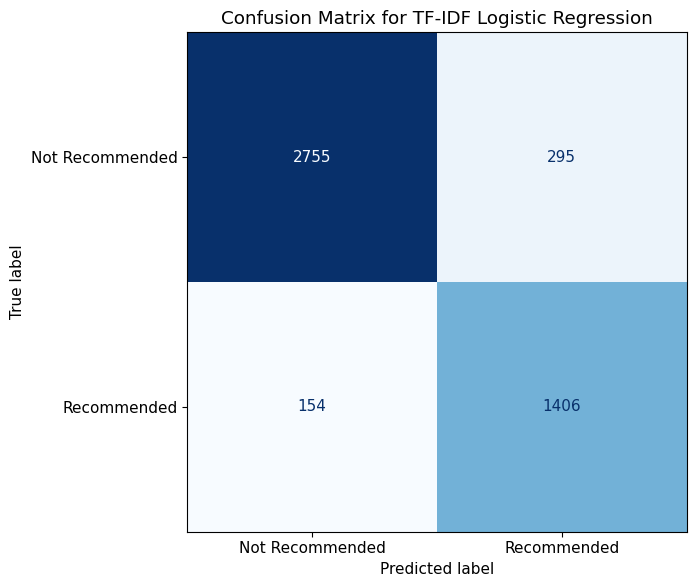


Confusion matrix:
[[2755  295]
 [ 154 1406]]


In [124]:
# ============================================================
# FIGURE 13: LOGISTIC REGRESSION CONFUSION MATRIX
# ============================================================

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_pred_lr
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Not Recommended",
        "Recommended"
    ]
)

fig, ax = plt.subplots(figsize=(7, 6))

disp.plot(
    ax=ax,
    values_format="d",
    cmap="Blues",
    colorbar=False
)

plt.title(
    "Confusion Matrix for TF-IDF Logistic Regression"
)

plt.tight_layout()
plt.show()

print("\nConfusion matrix:")
print(cm)

In [125]:
# ============================================================
# STEP 7F: MOST INFLUENTIAL TF-IDF FEATURES
# ============================================================

feature_names = np.array(
    tfidf.get_feature_names_out()
)

coefficients = logistic_model.coef_[0]

# Highest coefficients -> Recommended
positive_indices = np.argsort(
    coefficients
)[-20:][::-1]

# Lowest coefficients -> Not Recommended
negative_indices = np.argsort(
    coefficients
)[:20]

recommended_features = pd.DataFrame({
    "Feature": feature_names[positive_indices],
    "Coefficient": coefficients[positive_indices]
})

not_recommended_features = pd.DataFrame({
    "Feature": feature_names[negative_indices],
    "Coefficient": coefficients[negative_indices]
})

print("=" * 70)
print("FEATURES ASSOCIATED WITH RECOMMENDED REVIEWS")
print("=" * 70)

display(
    recommended_features.round(4)
)

print("\n" + "=" * 70)
print("FEATURES ASSOCIATED WITH NOT RECOMMENDED REVIEWS")
print("=" * 70)

display(
    not_recommended_features.round(4)
)

FEATURES ASSOCIATED WITH RECOMMENDED REVIEWS


,Feature,Coefficient
0,good,7.9904
1,thank,6.3823
2,excellent,6.0173
3,great,5.9950
4,nice,5.2034
5,comfortable,4.8998
6,smooth,4.5507
7,friendly,4.3161
8,professional,4.0971
9,easy,4.0517



FEATURES ASSOCIATED WITH NOT RECOMMENDED REVIEWS


,Feature,Coefficient
0,bad,-6.6862
1,poor,-4.5713
2,pay,-4.4289
3,rude,-4.3417
4,terrible,-3.9072
5,tell,-3.8100
6,avoid,-3.6469
7,hour,-3.6127
8,cancel,-3.5803
9,uncomfortable,-3.1938


In [126]:
# ============================================================
# STEP 8A: TRAIN LINEAR SVM
# ============================================================

from sklearn.svm import LinearSVC
import time

svm_model = LinearSVC(
    C=1.0,
    class_weight="balanced",
    random_state=42,
    max_iter=5000
)

print("=" * 70)
print("TRAINING LINEAR SVM")
print("=" * 70)

start_time = time.time()

svm_model.fit(
    X_train_tfidf,
    y_train
)

svm_training_time = time.time() - start_time

print("Training completed successfully.")
print(f"Training time: {svm_training_time:.2f} seconds")

TRAINING LINEAR SVM
Training completed successfully.
Training time: 0.36 seconds


In [127]:
# ============================================================
# STEP 8B: LINEAR SVM EVALUATION
# ============================================================

y_pred_svm = svm_model.predict(
    X_test_tfidf
)

svm_accuracy = accuracy_score(
    y_test,
    y_pred_svm
)

svm_precision = precision_score(
    y_test,
    y_pred_svm,
    average="weighted"
)

svm_recall = recall_score(
    y_test,
    y_pred_svm,
    average="weighted"
)

svm_f1_weighted = f1_score(
    y_test,
    y_pred_svm,
    average="weighted"
)

svm_f1_macro = f1_score(
    y_test,
    y_pred_svm,
    average="macro"
)

print("=" * 70)
print("LINEAR SVM PERFORMANCE")
print("=" * 70)

print(f"Accuracy:           {svm_accuracy:.4f}")
print(f"Weighted Precision: {svm_precision:.4f}")
print(f"Weighted Recall:    {svm_recall:.4f}")
print(f"Weighted F1:        {svm_f1_weighted:.4f}")
print(f"Macro F1:           {svm_f1_macro:.4f}")

print("\n" + "=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_test,
        y_pred_svm,
        target_names=[
            "Not Recommended",
            "Recommended"
        ],
        digits=4
    )
)

LINEAR SVM PERFORMANCE
Accuracy:           0.8987
Weighted Precision: 0.9001
Weighted Recall:    0.8987
Weighted F1:        0.8992
Macro F1:           0.8880

CLASSIFICATION REPORT
                 precision    recall  f1-score   support

Not Recommended     0.9327    0.9128    0.9226      3050
    Recommended     0.8363    0.8712    0.8534      1560

       accuracy                         0.8987      4610
      macro avg     0.8845    0.8920    0.8880      4610
   weighted avg     0.9001    0.8987    0.8992      4610



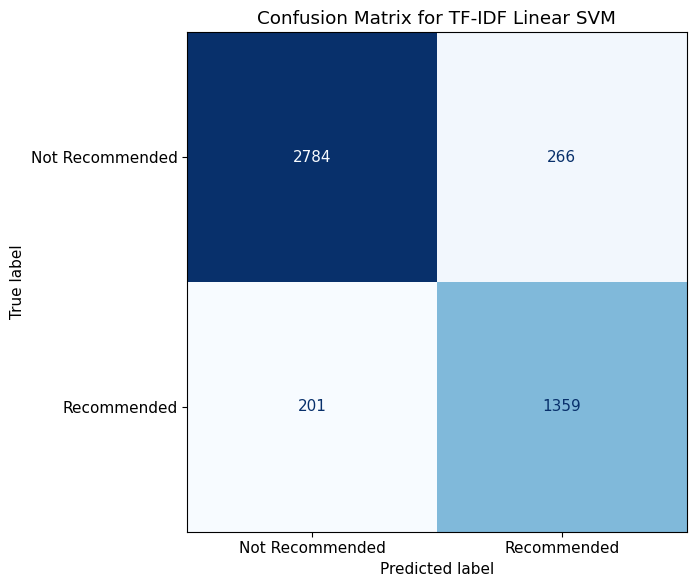

Confusion matrix:
[[2784  266]
 [ 201 1359]]


In [128]:
# ============================================================
# FIGURE 14: LINEAR SVM CONFUSION MATRIX
# ============================================================

cm_svm = confusion_matrix(
    y_test,
    y_pred_svm
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_svm,
    display_labels=[
        "Not Recommended",
        "Recommended"
    ]
)

fig, ax = plt.subplots(figsize=(7, 6))

disp.plot(
    ax=ax,
    values_format="d",
    cmap="Blues",
    colorbar=False
)

plt.title(
    "Confusion Matrix for TF-IDF Linear SVM"
)

plt.tight_layout()
plt.show()

print("Confusion matrix:")
print(cm_svm)

In [129]:
# ============================================================
# STEP 8D: CLASSICAL MODEL COMPARISON
# ============================================================

classical_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Linear SVM"
    ],

    "Accuracy": [
        lr_accuracy,
        svm_accuracy
    ],

    "Weighted Precision": [
        lr_precision,
        svm_precision
    ],

    "Weighted Recall": [
        lr_recall,
        svm_recall
    ],

    "Weighted F1": [
        lr_f1_weighted,
        svm_f1_weighted
    ],

    "Macro F1": [
        lr_f1_macro,
        svm_f1_macro
    ],

    "Training Time (s)": [
        logistic_training_time,
        svm_training_time
    ]
})

print("=" * 70)
print("CLASSICAL MODEL COMPARISON")
print("=" * 70)

display(
    classical_comparison.round(4)
)

CLASSICAL MODEL COMPARISON


,Model,Accuracy,Weighted Precision,Weighted Recall,Weighted F1,Macro F1,Training Time (s)
0,Logistic Regression,0.9026,0.9063,0.9026,0.9036,0.8935,1.2909
1,Linear SVM,0.8987,0.9001,0.8987,0.8992,0.8880,0.3587


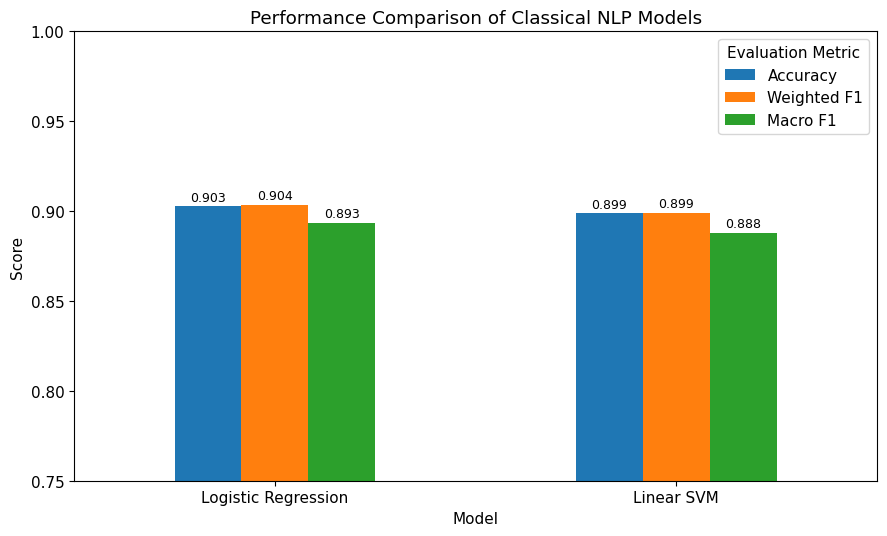

In [130]:
# ============================================================
# FIGURE 15: CLASSICAL MODEL PERFORMANCE
# ============================================================

comparison_plot = (
    classical_comparison
    .set_index("Model")[
        [
            "Accuracy",
            "Weighted F1",
            "Macro F1"
        ]
    ]
)

ax = comparison_plot.plot(
    kind="bar",
    figsize=(9, 5.5)
)

plt.title(
    "Performance Comparison of Classical NLP Models"
)

plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0.75, 1.0)
plt.xticks(rotation=0)
plt.legend(
    title="Evaluation Metric"
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=2,
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [131]:
# ============================================================
# STEP 8F: EXTRACT ACTUAL MISCLASSIFIED REVIEWS
# ============================================================

error_analysis = pd.DataFrame({
    "Review": df_clean.loc[X_test.index, "Review"],
    "True_Label": y_test,
    "LR_Prediction": y_pred_lr,
    "SVM_Prediction": y_pred_svm
})

# Human-readable labels
label_names = {
    0: "Not Recommended",
    1: "Recommended"
}

error_analysis["True_Class"] = (
    error_analysis["True_Label"]
    .map(label_names)
)

error_analysis["LR_Predicted_Class"] = (
    error_analysis["LR_Prediction"]
    .map(label_names)
)

error_analysis["SVM_Predicted_Class"] = (
    error_analysis["SVM_Prediction"]
    .map(label_names)
)

# Errors made by Logistic Regression
lr_errors = error_analysis[
    error_analysis["True_Label"] !=
    error_analysis["LR_Prediction"]
].copy()

# Errors made by SVM
svm_errors = error_analysis[
    error_analysis["True_Label"] !=
    error_analysis["SVM_Prediction"]
].copy()

print("=" * 70)
print("MISCLASSIFICATION COUNTS")
print("=" * 70)

print(
    f"Logistic Regression errors: "
    f"{len(lr_errors):,}"
)

print(
    f"Linear SVM errors: "
    f"{len(svm_errors):,}"
)

print("\n" + "=" * 70)
print("SAMPLE LOGISTIC REGRESSION ERRORS")
print("=" * 70)

display(
    lr_errors[
        [
            "Review",
            "True_Class",
            "LR_Predicted_Class"
        ]
    ].head(10)
)

print("\n" + "=" * 70)
print("SAMPLE LINEAR SVM ERRORS")
print("=" * 70)

display(
    svm_errors[
        [
            "Review",
            "True_Class",
            "SVM_Predicted_Class"
        ]
    ].head(10)
)

MISCLASSIFICATION COUNTS
Logistic Regression errors: 449
Linear SVM errors: 467

SAMPLE LOGISTIC REGRESSION ERRORS


,Review,True_Class,LR_Predicted_Class
21027,"Brussels to Montego Bay via Santo Domingo. Although we had a lot of problems with our flight, TUIFly managed the situation very well. On the day of departure, our flight from B...",Recommended,Not Recommended
11887,Sydney to Tokyo Narita. Sadly disappointed by Japan Airlines. While the crews and seating were superb the meals in premium economy (and economy) were just plain awful. I like ...,Not Recommended,Recommended
19549,When we were returning home from our vacation in Greece we had to go Athens - Larnaca Larnaca - Damascus. When we stopped at Larnaca it turned out that we would fly a Syrianair...,Not Recommended,Recommended
20759,Flew as part of British Airways booking flying from London Gatwick to Malaga. Head steward great with passengers but a couple of others were rude and officious! Nowhere near as...,Not Recommended,Recommended
10054,"Took my money. Said flight was changeable for no fee. Charged fee to change. Do not fly. If you want to throw money away, a recycling bin is easier. Customer service says they ...",Recommended,Not Recommended
6482,Port of Spain to London Gatwick. Customer service onboard and the warm hospitality of the flight attendants make this superior service. In addition to the edible onboard food (...,Recommended,Not Recommended
456,"What started as a very pleasant trip with Aerolineas Argentinas, ended up becoming one of the most bothersome long haul flights I have ever experienced. I flew from Rio de Jane...",Not Recommended,Recommended
2,Anjouan to Dzaoudzi. A very small airline and the only airline based in Comoros. Check-in was disorganised because of locals with big packages and disinterested staff. The flig...,Not Recommended,Recommended
2335,Glasgow to Lourdes this journey proved all the negative reviews I had read about this airline to be spot on. Plane arrived at Glasgow four hours late after which we eventually ...,Not Recommended,Recommended
16745,SYD-GTH-SYD-CMA-SYD over a few days. REX is a charming airline with excellent staff attitudes. Check-in in Sydney was very good. On arrival at your destination the First Office...,Not Recommended,Recommended



SAMPLE LINEAR SVM ERRORS


,Review,True_Class,SVM_Predicted_Class
21027,"Brussels to Montego Bay via Santo Domingo. Although we had a lot of problems with our flight, TUIFly managed the situation very well. On the day of departure, our flight from B...",Recommended,Not Recommended
20759,Flew as part of British Airways booking flying from London Gatwick to Malaga. Head steward great with passengers but a couple of others were rude and officious! Nowhere near as...,Not Recommended,Recommended
10054,"Took my money. Said flight was changeable for no fee. Charged fee to change. Do not fly. If you want to throw money away, a recycling bin is easier. Customer service says they ...",Recommended,Not Recommended
6482,Port of Spain to London Gatwick. Customer service onboard and the warm hospitality of the flight attendants make this superior service. In addition to the edible onboard food (...,Recommended,Not Recommended
456,"What started as a very pleasant trip with Aerolineas Argentinas, ended up becoming one of the most bothersome long haul flights I have ever experienced. I flew from Rio de Jane...",Not Recommended,Recommended
2,Anjouan to Dzaoudzi. A very small airline and the only airline based in Comoros. Check-in was disorganised because of locals with big packages and disinterested staff. The flig...,Not Recommended,Recommended
2335,Glasgow to Lourdes this journey proved all the negative reviews I had read about this airline to be spot on. Plane arrived at Glasgow four hours late after which we eventually ...,Not Recommended,Recommended
14860,ZB238/239 3rd-10th January. I have flown Monarch 4x times this year and have to write as they have improved immensely in the past 12 months. The check-in facility at Gatwick is...,Recommended,Not Recommended
19619,LIS to LAD. The flight was delayed seven hours - first because of a mechanical problem and then because of the airport curfew in LIS. This left only 30 minutes to make our conn...,Not Recommended,Recommended
20706,Melbourne to Sydney. Travelling home to Coffs Harbour after a family wedding Tiger cancelled our flight due to an apparent Lightning strike. Refund was offered but we were out ...,Not Recommended,Recommended


In [132]:
# ============================================================
# STEP 8G: REVIEWS MISCLASSIFIED BY BOTH CLASSICAL MODELS
# ============================================================

shared_errors = error_analysis[
    (error_analysis["True_Label"] != error_analysis["LR_Prediction"])
    &
    (error_analysis["True_Label"] != error_analysis["SVM_Prediction"])
].copy()

print("=" * 70)
print("SHARED MISCLASSIFICATIONS")
print("=" * 70)

print(
    f"Reviews misclassified by both models: "
    f"{len(shared_errors):,}"
)

# Show complete review text rather than truncated dataframe text
for number, (idx, row) in enumerate(
    shared_errors.head(10).iterrows(),
    start=1
):
    print("\n" + "=" * 70)
    print(f"SHARED ERROR {number}")
    print("=" * 70)

    print(f"Dataset index: {idx}")
    print(f"True class: {row['True_Class']}")
    print(
        f"Logistic Regression prediction: "
        f"{row['LR_Predicted_Class']}"
    )
    print(
        f"Linear SVM prediction: "
        f"{row['SVM_Predicted_Class']}"
    )

    print("\nFull review:")
    print(row["Review"])

SHARED MISCLASSIFICATIONS
Reviews misclassified by both models: 373

SHARED ERROR 1
Dataset index: 21027
True class: Recommended
Logistic Regression prediction: Not Recommended
Linear SVM prediction: Not Recommended

Full review:
Brussels to Montego Bay via Santo Domingo. Although we had a lot of problems with our flight, TUIFly managed the situation very well. On the day of departure, our flight from Brussels to Montego Bay got canceled because of some technical issues with the airplane. We were really upset because we were supposed to leave for our honeymoon, so all our anger was directed towards TUI. They explained to us what has happened and that we shall leave the next day, so they provided accommodation, meals and transfers. Everything was very well organized and the staff was very helpful. After coming back from our honeymoon, we also filed a complaint for the delay resulting in us missing one night in Jamaica, and the airline compensated us, no questions asked, according to the

In [133]:
# ============================================================
# STEP 9A: CHECK COLAB HARDWARE
# ============================================================

import torch

print("=" * 70)
print("COLAB HARDWARE CHECK")
print("=" * 70)

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    device = "cuda"
else:
    print("GPU unavailable - CPU will be used.")
    device = "cpu"

print("Selected device:", device)

COLAB HARDWARE CHECK
PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
Selected device: cuda


In [134]:
# ============================================================
# STEP 9B: CREATE STRATIFIED EMBEDDING SAMPLE
# ============================================================

from sklearn.model_selection import train_test_split

embedding_df, _ = train_test_split(
    df_clean,
    train_size=5000,
    random_state=42,
    stratify=df_clean["Sentiment_Label"]
)

embedding_df = embedding_df.copy().reset_index(drop=True)

print("=" * 70)
print("SEMANTIC EMBEDDING SAMPLE")
print("=" * 70)

print(f"Sample size: {len(embedding_df):,}")

print("\nClass counts:")
print(
    embedding_df["Sentiment_Class"]
    .value_counts()
)

print("\nClass percentages:")
print(
    embedding_df["Sentiment_Class"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nAverage review length:")
print(
    embedding_df["Review_Length_Words"]
    .mean()
    .round(2)
)

SEMANTIC EMBEDDING SAMPLE
Sample size: 5,000

Class counts:
Sentiment_Class
Not Recommended    3308
Recommended        1692
Name: count, dtype: int64

Class percentages:
Sentiment_Class
Not Recommended    66.16
Recommended        33.84
Name: proportion, dtype: float64

Average review length:
129.79


In [135]:
# ============================================================
# STEP 9C: LOAD SENTENCE TRANSFORMER
# ============================================================

!pip -q install -U sentence-transformers

from sentence_transformers import SentenceTransformer
import time

print("=" * 70)
print("LOADING SENTENCE TRANSFORMER")
print("=" * 70)

embedding_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2",
    device=device
)

print("Model loaded successfully.")
print(
    "Embedding dimension:",
    embedding_model.get_sentence_embedding_dimension()
)

LOADING SENTENCE TRANSFORMER


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Model loaded successfully.
Embedding dimension: 384


/tmp/ipykernel_1683/3326245951.py:22: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  embedding_model.get_sentence_embedding_dimension()


In [136]:
# ============================================================
# STEP 9D: GENERATE SENTENCE EMBEDDINGS
# ============================================================

reviews_for_embedding = (
    embedding_df["Review"]
    .astype(str)
    .tolist()
)

print("=" * 70)
print("GENERATING SEMANTIC EMBEDDINGS")
print("=" * 70)

start_time = time.time()

review_embeddings = embedding_model.encode(
    reviews_for_embedding,
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)

embedding_time = time.time() - start_time

print("\nEmbedding generation completed.")

print(
    "Embedding matrix shape:",
    review_embeddings.shape
)

print(
    f"Processing time: "
    f"{embedding_time:.2f} seconds"
)

print(
    "Data type:",
    review_embeddings.dtype
)

memory_mb = (
    review_embeddings.nbytes /
    (1024 ** 2)
)

print(
    f"Embedding matrix memory: "
    f"{memory_mb:.2f} MB"
)

GENERATING SEMANTIC EMBEDDINGS


Batches:   0%|          | 0/157 [00:00<?, ?it/s]


Embedding generation completed.
Embedding matrix shape: (5000, 384)
Processing time: 14.12 seconds
Data type: float32
Embedding matrix memory: 7.32 MB


In [137]:
# ============================================================
# STEP 9E: COSINE SIMILARITY DEMONSTRATION
# ============================================================

from sklearn.metrics.pairwise import cosine_similarity

example_indices = [0, 1, 2]

example_similarity = cosine_similarity(
    review_embeddings[example_indices]
)

print("=" * 70)
print("COSINE SIMILARITY EXAMPLE")
print("=" * 70)

for i in example_indices:
    print(f"\nReview {i}:")
    print(
        embedding_df.loc[i, "Review"][:400]
    )

print("\nCosine similarity matrix:")
print(
    np.round(
        example_similarity,
        4
    )
)

COSINE SIMILARITY EXAMPLE

Review 0:
Staff was friendly and helpful on check-in, but all my impression was spoilt when I found my dog in Toronto being not in his native box. We arrived in Frankfurt airport with our own box, which we use day-to-day for travelling and for resting at home. It was our property and a box, which my dog got used to. The staff checked this box entirely, approved its condition, we closed the door and they too

Review 1:
Nashville to Chicago. My initial flight was an hour and a half late. No reason for the delay was given. I ran through the airport to catch my connecting flight and they refused to let me board with 10 minutes to spare. The plane was still stationary and attached to the gate 25 minutes later. I asked them the soonest they could get me a flight to my destination and they replied curtly. "4 PM, tomor

Review 2:
Singapore to Penang. First time on SilkAir so did not know what to expect given the limited reviews. Check in was T2 and used the KrisFlyer

In [138]:
# ============================================================
# STEP 9F: SEMANTIC COMPLAINT RETRIEVAL FUNCTION
# ============================================================

def retrieve_similar_reviews(
    query,
    top_k=5
):
    """
    Retrieve semantically similar airline reviews
    using Sentence Transformer embeddings.
    """

    query_embedding = embedding_model.encode(
        [query],
        convert_to_numpy=True,
        normalize_embeddings=True
    )

    similarities = cosine_similarity(
        query_embedding,
        review_embeddings
    )[0]

    top_indices = np.argsort(
        similarities
    )[::-1][:top_k]

    results = embedding_df.loc[
        top_indices,
        [
            "Airline Name",
            "Review",
            "Sentiment_Class"
        ]
    ].copy()

    results["Cosine_Similarity"] = (
        similarities[top_indices]
    )

    return results.reset_index(drop=True)

In [139]:
# ============================================================
# RETRIEVAL TEST 1: FLIGHT DELAY
# ============================================================

query_1 = "My flight was delayed for several hours"

print("=" * 70)
print("QUERY:")
print(query_1)
print("=" * 70)

results_1 = retrieve_similar_reviews(
    query_1,
    top_k=5
)

display(results_1)

QUERY:
My flight was delayed for several hours


,Airline Name,Review,Sentiment_Class,Cosine_Similarity
0,Swoop,Our flight was delayed by approximately 4 hours. I have tried to contact them to be compensated for this and I have heard nothing back from them. They had already delayed the f...,Not Recommended,0.695926
1,United Airlines,Their customer service is poor and we were delayed tried transferring to another airline wouldn't to that. Talked to the next morning who said we could have taken a connecting ...,Not Recommended,0.679501
2,Scoot,My flight in February was delayed for 5 hours. It was a morning flight and they sent an email during midnight 3am telling me that flight been changed to noon. But when I was in...,Not Recommended,0.679050
3,Egyptair,"As Soon as I booked the flight they didn't tell me it was going to be delayed! I even booked the flight several hours before boarding. Within I was checking in, they told me it...",Not Recommended,0.678290
4,AirAsia Philippines,"Our flight from Manila to Hong Kong from NAIA Terminal 3 was delayed by an hour. Our flight was supposed to be at 6:15pm and they delayed it by 2 hours (8:15pm). At the time, t...",Not Recommended,0.669423


In [140]:
# ============================================================
# RETRIEVAL TEST 2: CUSTOMER SERVICE
# ============================================================

query_2 = "Customer service was rude and unhelpful"

print("=" * 70)
print("QUERY:")
print(query_2)
print("=" * 70)

results_2 = retrieve_similar_reviews(
    query_2,
    top_k=5
)

display(results_2)

QUERY:
Customer service was rude and unhelpful


,Airline Name,Review,Sentiment_Class,Cosine_Similarity
0,Air France,Customer service on the phone were both incompetent and rude. Took 4 days of being told to call back in 24h and receiving no help. Every person we spoke to at the check in desk...,Not Recommended,0.649883
1,Eurowings,Worst customer experience and service ever. No answers on the phone for hours. The customer service personnel are rude and refuse to help even if it’s there own fault. The syst...,Not Recommended,0.610899
2,Airlink,"From the baggage check in, the boarding gates and the flight itself, the staff was so unnecessarily rude. My family and I were last at the gate with 15 minutes to spare before ...",Not Recommended,0.604418
3,Jetblue Airways,Very unprofessional. Flight was cancelled with out information The service person was rude and unprofessional. Gave food voucher but not happy with the unprofessional attitude ...,Not Recommended,0.590329
4,Alitalia,"I’ve never seen such a bad company. Rude people. No service at all. They lost my luggage. Well it has been on ""delivery"" for the last 2 days…. Terrible choice",Not Recommended,0.588311


In [141]:
# ============================================================
# RETRIEVAL TEST 3: BAGGAGE
# ============================================================

query_3 = "The airline lost my baggage"

print("=" * 70)
print("QUERY:")
print(query_3)
print("=" * 70)

results_3 = retrieve_similar_reviews(
    query_3,
    top_k=5
)

display(results_3)

QUERY:
The airline lost my baggage


,Airline Name,Review,Sentiment_Class,Cosine_Similarity
0,Jazeera Airways,"If you are keen to lose your baggage and being treated as cattle go fo it! The airline managed to load my bag to Pakistan (as it turned out eventually), although I was going to...",Not Recommended,0.716882
1,SriLankan Airlines,"Lost bag and completely failed to take responsibility. Extremely slow and difficult to deal with, constantly refusing to help locate the baggage and insisting it was nothing to...",Not Recommended,0.697540
2,Philippine Airlines,Lost my bag! Terrible airline could not account for my bag on a straight flight. I waited 1.5 hours at the destination carousel and my bag never came. Customer service via emai...,Not Recommended,0.695248
3,Finnair,Worst airline ever. There’s actually no customer service. They lost my bag and they don’t answer the phone I had to go to the airport many times to talk to them but they ignore...,Not Recommended,0.692943
4,Austrian Airlines,Baggage has been lost for seven days and you cannot get in contact with with anyone and there has been no communication. It has ruined our vacation. I understand if there was ...,Not Recommended,0.681144


In [142]:
# ============================================================
# STEP 10A: PCA OF SENTENCE EMBEDDINGS
# ============================================================

from sklearn.decomposition import PCA
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pca = PCA(
    n_components=2,
    random_state=42
)

pca_embeddings = pca.fit_transform(
    review_embeddings
)

embedding_df["PCA_1"] = pca_embeddings[:, 0]
embedding_df["PCA_2"] = pca_embeddings[:, 1]

print("=" * 70)
print("PCA RESULTS")
print("=" * 70)

print(
    "PCA output shape:",
    pca_embeddings.shape
)

print(
    "PC1 explained variance:",
    round(
        pca.explained_variance_ratio_[0],
        4
    )
)

print(
    "PC2 explained variance:",
    round(
        pca.explained_variance_ratio_[1],
        4
    )
)

print(
    "Combined explained variance:",
    round(
        pca.explained_variance_ratio_.sum(),
        4
    )
)

PCA RESULTS
PCA output shape: (5000, 2)
PC1 explained variance: 0.0809
PC2 explained variance: 0.037
Combined explained variance: 0.1179


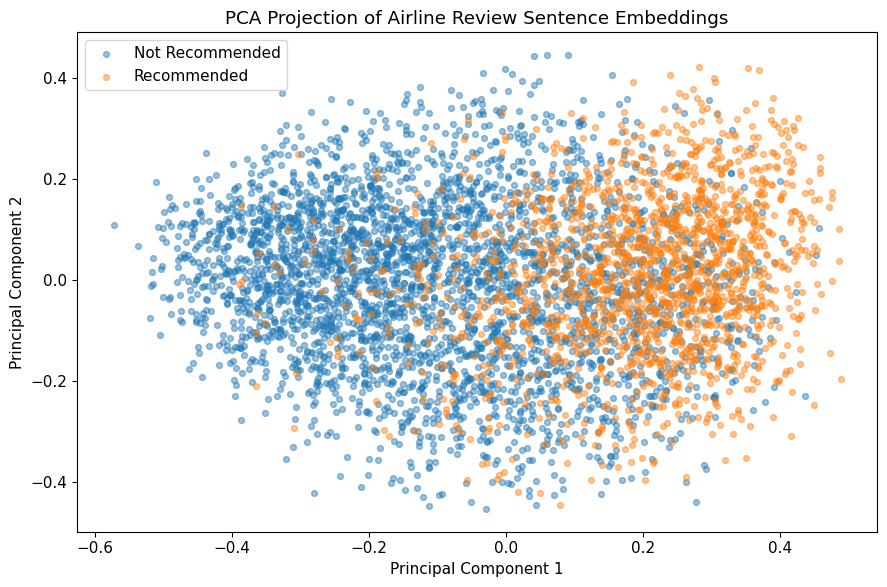

In [143]:
# ============================================================
# FIGURE 16: PCA VISUALISATION
# ============================================================

plt.figure(figsize=(9, 6))

for label, class_name in [
    (0, "Not Recommended"),
    (1, "Recommended")
]:

    mask = (
        embedding_df["Sentiment_Label"]
        == label
    )

    plt.scatter(
        embedding_df.loc[mask, "PCA_1"],
        embedding_df.loc[mask, "PCA_2"],
        alpha=0.45,
        s=18,
        label=class_name
    )

plt.title(
    "PCA Projection of Airline Review Sentence Embeddings"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()

plt.tight_layout()
plt.show()

In [144]:
# ============================================================
# STEP 10B: STRATIFIED t-SNE SUBSET
# ============================================================

from sklearn.model_selection import train_test_split

tsne_indices, _ = train_test_split(
    np.arange(len(embedding_df)),
    train_size=2000,
    random_state=42,
    stratify=embedding_df["Sentiment_Label"]
)

tsne_embeddings_input = (
    review_embeddings[tsne_indices]
)

tsne_labels = (
    embedding_df
    .iloc[tsne_indices]["Sentiment_Label"]
    .to_numpy()
)

print("=" * 70)
print("t-SNE SAMPLE")
print("=" * 70)

print(
    "Embedding input shape:",
    tsne_embeddings_input.shape
)

unique, counts = np.unique(
    tsne_labels,
    return_counts=True
)

print("\nClass distribution:")

for label, count in zip(
    unique,
    counts
):
    print(
        label,
        ":",
        count
    )

t-SNE SAMPLE
Embedding input shape: (2000, 384)

Class distribution:
0 : 1323
1 : 677


In [145]:
# ============================================================
# STEP 10C: PCA REDUCTION BEFORE t-SNE
# ============================================================

pca_50 = PCA(
    n_components=50,
    random_state=42
)

tsne_input_50 = pca_50.fit_transform(
    tsne_embeddings_input
)

print("=" * 70)
print("PCA PREPROCESSING FOR t-SNE")
print("=" * 70)

print(
    "Original dimensions:",
    tsne_embeddings_input.shape
)

print(
    "Reduced dimensions:",
    tsne_input_50.shape
)

print(
    "Variance retained by 50 PCs:",
    round(
        pca_50.explained_variance_ratio_.sum(),
        4
    )
)

PCA PREPROCESSING FOR t-SNE
Original dimensions: (2000, 384)
Reduced dimensions: (2000, 50)
Variance retained by 50 PCs: 0.6382


In [146]:
# ============================================================
# STEP 10D: t-SNE
# ============================================================

from sklearn.manifold import TSNE
import time

print("=" * 70)
print("RUNNING t-SNE")
print("=" * 70)

start_time = time.time()

tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    max_iter=1000,
    random_state=42
)

tsne_coordinates = tsne.fit_transform(
    tsne_input_50
)

tsne_time = time.time() - start_time

print("t-SNE completed successfully.")

print(
    "Output shape:",
    tsne_coordinates.shape
)

print(
    f"Processing time: "
    f"{tsne_time:.2f} seconds"
)

print(
    f"KL divergence: "
    f"{tsne.kl_divergence_:.4f}"
)

RUNNING t-SNE
t-SNE completed successfully.
Output shape: (2000, 2)
Processing time: 37.15 seconds
KL divergence: 2.0545


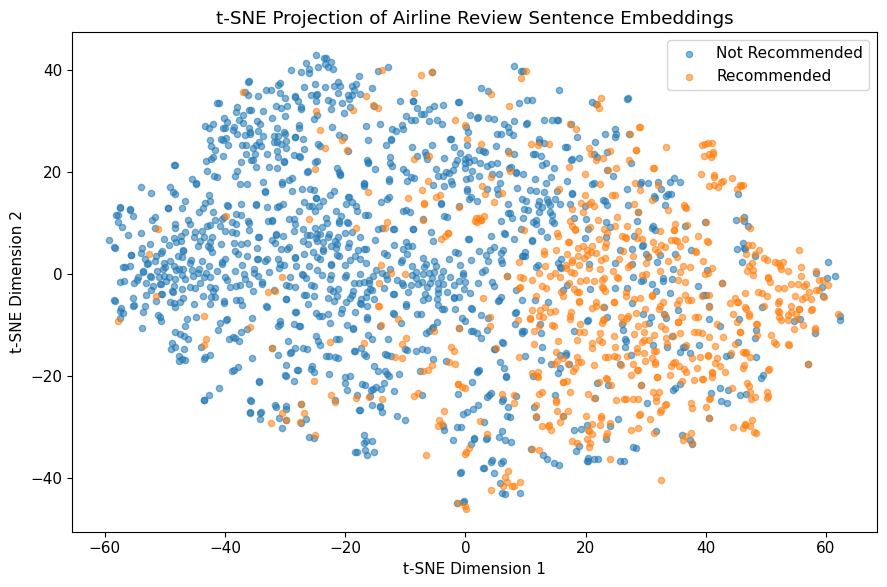

In [147]:
# ============================================================
# FIGURE 17: t-SNE VISUALISATION
# ============================================================

plt.figure(figsize=(9, 6))

for label, class_name in [
    (0, "Not Recommended"),
    (1, "Recommended")
]:

    mask = tsne_labels == label

    plt.scatter(
        tsne_coordinates[mask, 0],
        tsne_coordinates[mask, 1],
        alpha=0.55,
        s=20,
        label=class_name
    )

plt.title(
    "t-SNE Projection of Airline Review Sentence Embeddings"
)

plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.legend()

plt.tight_layout()
plt.show()

In [148]:
# ============================================================
# STEP 10F: WITHIN-CLASS VS BETWEEN-CLASS SIMILARITY
# ============================================================

rng = np.random.default_rng(42)

labels = embedding_df[
    "Sentiment_Label"
].to_numpy()

negative_indices = np.where(
    labels == 0
)[0]

positive_indices = np.where(
    labels == 1
)[0]

n_pairs = 1000

# ------------------------------------------
# Same-class pairs
# ------------------------------------------

same_class_similarities = []

for _ in range(n_pairs):

    selected_class = rng.choice(
        [0, 1]
    )

    pool = (
        negative_indices
        if selected_class == 0
        else positive_indices
    )

    i, j = rng.choice(
        pool,
        size=2,
        replace=False
    )

    similarity = np.dot(
        review_embeddings[i],
        review_embeddings[j]
    )

    same_class_similarities.append(
        similarity
    )

# ------------------------------------------
# Different-class pairs
# ------------------------------------------

different_class_similarities = []

for _ in range(n_pairs):

    i = rng.choice(
        negative_indices
    )

    j = rng.choice(
        positive_indices
    )

    similarity = np.dot(
        review_embeddings[i],
        review_embeddings[j]
    )

    different_class_similarities.append(
        similarity
    )

print("=" * 70)
print("SEMANTIC SIMILARITY ANALYSIS")
print("=" * 70)

print(
    "Mean same-class cosine similarity:",
    round(
        np.mean(
            same_class_similarities
        ),
        4
    )
)

print(
    "Mean different-class cosine similarity:",
    round(
        np.mean(
            different_class_similarities
        ),
        4
    )
)

print(
    "Median same-class similarity:",
    round(
        np.median(
            same_class_similarities
        ),
        4
    )
)

print(
    "Median different-class similarity:",
    round(
        np.median(
            different_class_similarities
        ),
        4
    )
)

SEMANTIC SIMILARITY ANALYSIS
Mean same-class cosine similarity: 0.3508
Mean different-class cosine similarity: 0.3011
Median same-class similarity: 0.3506
Median different-class similarity: 0.2997


In [149]:
# ============================================================
# STEP 11A: PREPARE DISTILBERT DATASET
# ============================================================

from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np

# Reproducible stratified sample
bert_df, _ = train_test_split(
    df_clean[["Review", "Sentiment_Label"]],
    train_size=4000,
    random_state=42,
    stratify=df_clean["Sentiment_Label"]
)

bert_df = bert_df.reset_index(drop=True)

# 80% training, 20% temporary
bert_train, bert_temp = train_test_split(
    bert_df,
    test_size=0.20,
    random_state=42,
    stratify=bert_df["Sentiment_Label"]
)

# Divide temporary set equally:
# 10% validation and 10% testing
bert_val, bert_test = train_test_split(
    bert_temp,
    test_size=0.50,
    random_state=42,
    stratify=bert_temp["Sentiment_Label"]
)

print("=" * 70)
print("DISTILBERT DATASET PREPARATION")
print("=" * 70)

print(f"Complete transformer sample: {len(bert_df):,}")
print(f"Training reviews:            {len(bert_train):,}")
print(f"Validation reviews:          {len(bert_val):,}")
print(f"Testing reviews:             {len(bert_test):,}")

for name, frame in [
    ("Training", bert_train),
    ("Validation", bert_val),
    ("Testing", bert_test)
]:
    print(f"\n{name} distribution:")
    print(frame["Sentiment_Label"].value_counts())

    print(f"{name} percentages:")
    print(
        frame["Sentiment_Label"]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )

DISTILBERT DATASET PREPARATION
Complete transformer sample: 4,000
Training reviews:            3,200
Validation reviews:          400
Testing reviews:             400

Training distribution:
Sentiment_Label
0    2118
1    1082
Name: count, dtype: int64
Training percentages:
Sentiment_Label
0    66.19
1    33.81
Name: proportion, dtype: float64

Validation distribution:
Sentiment_Label
0    264
1    136
Name: count, dtype: int64
Validation percentages:
Sentiment_Label
0    66.0
1    34.0
Name: proportion, dtype: float64

Testing distribution:
Sentiment_Label
0    265
1    135
Name: count, dtype: int64
Testing percentages:
Sentiment_Label
0    66.25
1    33.75
Name: proportion, dtype: float64


In [150]:
# ============================================================
# STEP 11B: LOAD TOKENIZER AND INSPECT TOKEN LENGTHS
# ============================================================

!pip -q install -U transformers datasets accelerate evaluate

from transformers import AutoTokenizer

model_name = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(
    model_name
)

sample_token_lengths = []

for text in bert_df["Review"]:
    encoded = tokenizer(
        str(text),
        add_special_tokens=True,
        truncation=False
    )

    sample_token_lengths.append(
        len(encoded["input_ids"])
    )

token_lengths = np.array(
    sample_token_lengths
)

print("=" * 70)
print("DISTILBERT TOKEN LENGTH ANALYSIS")
print("=" * 70)

print(f"Minimum:        {token_lengths.min()}")
print(f"Median:         {np.median(token_lengths):.0f}")
print(f"Mean:           {token_lengths.mean():.2f}")
print(f"75th percentile:{np.percentile(token_lengths, 75):.0f}")
print(f"90th percentile:{np.percentile(token_lengths, 90):.0f}")
print(f"95th percentile:{np.percentile(token_lengths, 95):.0f}")
print(f"99th percentile:{np.percentile(token_lengths, 99):.0f}")
print(f"Maximum:        {token_lengths.max()}")

print("\nPercentage fitting within 128 tokens:")
print(
    round(
        (token_lengths <= 128).mean() * 100,
        2
    ),
    "%"
)

print("Percentage fitting within 256 tokens:")
print(
    round(
        (token_lengths <= 256).mean() * 100,
        2
    ),
    "%"
)

print("Percentage fitting within 512 tokens:")
print(
    round(
        (token_lengths <= 512).mean() * 100,
        2
    ),
    "%"
)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (673 > 512). Running this sequence through the model will result in indexing errors


DISTILBERT TOKEN LENGTH ANALYSIS
Minimum:        17
Median:         124
Mean:           156.51
75th percentile:195
90th percentile:301
95th percentile:380
99th percentile:614
Maximum:        1122

Percentage fitting within 128 tokens:
52.45 %
Percentage fitting within 256 tokens:
85.4 %
Percentage fitting within 512 tokens:
98.1 %


In [151]:
# ============================================================
# STEP 12A: CREATE HUGGING FACE DATASETS
# ============================================================

from datasets import Dataset

train_dataset = Dataset.from_pandas(
    bert_train[["Review", "Sentiment_Label"]],
    preserve_index=False
)

val_dataset = Dataset.from_pandas(
    bert_val[["Review", "Sentiment_Label"]],
    preserve_index=False
)

test_dataset = Dataset.from_pandas(
    bert_test[["Review", "Sentiment_Label"]],
    preserve_index=False
)

# Rename target for Hugging Face Trainer
train_dataset = train_dataset.rename_column(
    "Sentiment_Label", "labels"
)

val_dataset = val_dataset.rename_column(
    "Sentiment_Label", "labels"
)

test_dataset = test_dataset.rename_column(
    "Sentiment_Label", "labels"
)

print("=" * 70)
print("HUGGING FACE DATASETS")
print("=" * 70)

print(train_dataset)
print(val_dataset)
print(test_dataset)

HUGGING FACE DATASETS
Dataset({
    features: ['Review', 'labels'],
    num_rows: 3200
})
Dataset({
    features: ['Review', 'labels'],
    num_rows: 400
})
Dataset({
    features: ['Review', 'labels'],
    num_rows: 400
})


In [152]:
# ============================================================
# STEP 12B: TOKENIZE DATASETS
# ============================================================

MAX_LENGTH = 256

def tokenize_function(batch):
    return tokenizer(
        batch["Review"],
        truncation=True,
        max_length=MAX_LENGTH
        # No padding here: dynamic padding is used later
    )

tokenized_train = train_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["Review"]
)

tokenized_val = val_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["Review"]
)

tokenized_test = test_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["Review"]
)

print("=" * 70)
print("TOKENIZATION COMPLETE")
print("=" * 70)

print("Training examples:", len(tokenized_train))
print("Validation examples:", len(tokenized_val))
print("Testing examples:", len(tokenized_test))

print("\nFirst tokenized example:")
print(tokenized_train[0])

Map:   0%|          | 0/3200 [00:00<?, ? examples/s]

Map:   0%|          | 0/400 [00:00<?, ? examples/s]

Map:   0%|          | 0/400 [00:00<?, ? examples/s]

TOKENIZATION COMPLETE
Training examples: 3200
Validation examples: 400
Testing examples: 400

First tokenized example:
{'labels': 0, 'input_ids': [101, 8955, 2000, 5185, 14346, 3081, 6768, 1012, 3479, 1996, 3462, 2349, 2000, 2560, 4390, 1997, 2025, 5278, 1996, 4946, 2012, 6768, 1998, 3825, 4469, 13258, 2005, 2835, 4989, 1012, 2009, 2001, 2204, 6229, 2057, 5565, 2012, 6768, 1012, 2045, 1045, 2001, 4375, 1037, 2047, 9405, 3413, 1998, 2001, 2081, 2000, 2448, 2013, 2028, 4946, 2000, 2178, 9405, 4796, 14996, 1996, 3036, 2320, 2153, 1012, 1996, 8582, 2018, 2904, 1996, 3462, 1998, 2130, 2904, 1996, 2835, 2004, 2566, 2037, 3601, 2302, 1037, 2773, 1997, 3374, 1012, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1,

In [153]:
# ============================================================
# STEP 12C: LOAD DISTILBERT CLASSIFIER
# ============================================================

from transformers import AutoModelForSequenceClassification
import torch

id2label = {
    0: "Not Recommended",
    1: "Recommended"
}

label2id = {
    "Not Recommended": 0,
    "Recommended": 1
}

bert_model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2,
    id2label=id2label,
    label2id=label2id
)

bert_model.to(device)

print("=" * 70)
print("DISTILBERT CLASSIFIER LOADED")
print("=" * 70)

print("Model:", model_name)
print("Number of labels:", bert_model.config.num_labels)
print("Device:", next(bert_model.parameters()).device)

total_parameters = sum(
    p.numel()
    for p in bert_model.parameters()
)

trainable_parameters = sum(
    p.numel()
    for p in bert_model.parameters()
    if p.requires_grad
)

print(f"Total parameters: {total_parameters:,}")
print(f"Trainable parameters: {trainable_parameters:,}")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DISTILBERT CLASSIFIER LOADED
Model: distilbert-base-uncased
Number of labels: 2
Device: cuda:0
Total parameters: 66,955,010
Trainable parameters: 66,955,010


In [154]:
# ============================================================
# STEP 12D: EVALUATION METRICS
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(
        logits,
        axis=-1
    )

    accuracy = accuracy_score(
        labels,
        predictions
    )

    precision_w, recall_w, f1_w, _ = (
        precision_recall_fscore_support(
            labels,
            predictions,
            average="weighted",
            zero_division=0
        )
    )

    precision_m, recall_m, f1_m, _ = (
        precision_recall_fscore_support(
            labels,
            predictions,
            average="macro",
            zero_division=0
        )
    )

    return {
        "accuracy": accuracy,
        "weighted_precision": precision_w,
        "weighted_recall": recall_w,
        "weighted_f1": f1_w,
        "macro_precision": precision_m,
        "macro_recall": recall_m,
        "macro_f1": f1_m
    }

print("Metric function ready.")

Metric function ready.


In [155]:
# ============================================================
# STEP 12E: DYNAMIC PADDING
# ============================================================

from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

print("Dynamic padding configured.")

Dynamic padding configured.


In [156]:
# ============================================================
# STEP 12F: TRAINING CONFIGURATION
# ============================================================

from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="/content/distilbert_airline_results",

    # Training
    num_train_epochs=3,
    learning_rate=2e-5,
    weight_decay=0.01,

    # T4-safe batches
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,

    # Evaluate and save after every epoch
    eval_strategy="epoch",
    save_strategy="epoch",

    # Keep best checkpoint
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,

    # Tesla T4 supports FP16
    fp16=True,

    # Logging
    logging_strategy="steps",
    logging_steps=25,

    # Avoid unnecessary checkpoint accumulation
    save_total_limit=2,

    # Reproducibility
    seed=42,
    data_seed=42,

    # Cleaner Colab output
    report_to="none"
)

print("=" * 70)
print("TRAINING CONFIGURATION")
print("=" * 70)

print("Epochs: 3")
print("Train batch size: 16")
print("Evaluation batch size: 32")
print("Learning rate: 2e-5")
print("Maximum sequence length: 256")
print("FP16:", training_args.fp16)
print("Best-model metric: Macro F1")

TRAINING CONFIGURATION
Epochs: 3
Train batch size: 16
Evaluation batch size: 32
Learning rate: 2e-5
Maximum sequence length: 256
FP16: True
Best-model metric: Macro F1


In [157]:
# ============================================================
# STEP 12G: CREATE TRAINER
# ============================================================

from transformers import Trainer

trainer = Trainer(
    model=bert_model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

print("Trainer created successfully.")

Trainer created successfully.


In [158]:
# ============================================================
# STEP 12H: FINE-TUNE DISTILBERT
# ============================================================

import time

print("=" * 70)
print("STARTING DISTILBERT FINE-TUNING")
print("=" * 70)

start_time = time.time()

train_result = trainer.train()

bert_training_time = (
    time.time() - start_time
)

print("\n" + "=" * 70)
print("TRAINING COMPLETE")
print("=" * 70)

print(
    f"Total training time: "
    f"{bert_training_time:.2f} seconds"
)

print(
    f"Total training time: "
    f"{bert_training_time / 60:.2f} minutes"
)

print(
    "Best checkpoint:",
    trainer.state.best_model_checkpoint
)

print(
    "Best validation metric:",
    trainer.state.best_metric
)

STARTING DISTILBERT FINE-TUNING


Epoch,Training Loss,Validation Loss,Accuracy,Weighted Precision,Weighted Recall,Weighted F1,Macro Precision,Macro Recall,Macro F1
1,0.180876,0.326732,0.890000,0.904473,0.890000,0.892150,0.873597,0.904189,0.882976
2,0.273566,0.292785,0.905000,0.910331,0.905000,0.906155,0.889007,0.908422,0.896918
3,0.253882,0.334104,0.902500,0.908385,0.902500,0.903746,0.886230,0.906529,0.894365


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


TRAINING COMPLETE
Total training time: 107.23 seconds
Total training time: 1.79 minutes
Best checkpoint: /content/distilbert_airline_results/checkpoint-400
Best validation metric: 0.8969184027777778


In [159]:
# ============================================================
# STEP 12I: TRAINING HISTORY
# ============================================================

history = trainer.state.log_history

history_df = pd.DataFrame(history)

print("=" * 70)
print("TRAINING LOG HISTORY")
print("=" * 70)

display(history_df)

TRAINING LOG HISTORY


,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_accuracy,eval_weighted_precision,eval_weighted_recall,eval_weighted_f1,...,eval_macro_recall,eval_macro_f1,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
0,0.616201,1.596257,1.920000e-05,0.125,25,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.372703,4.394990,1.836667e-05,0.250,50,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0.307750,1.683490,1.753333e-05,0.375,75,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.302714,2.097779,1.670000e-05,0.500,100,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0.199240,9.001662,1.586667e-05,0.625,125,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,0.239256,13.173656,1.503333e-05,0.750,150,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,0.355648,6.229855,1.420000e-05,0.875,175,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,0.180876,7.102714,1.336667e-05,1.000,200,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,NaN,NaN,1.000,200,0.326732,0.8900,0.904473,0.8900,0.892150,...,0.904189,0.882976,1.2526,319.333,10.378,NaN,NaN,NaN,NaN,NaN
9,0.197458,1.140653,1.253333e-05,1.125,225,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [160]:
# ============================================================
# VALIDATION HISTORY
# ============================================================

validation_history = history_df[
    history_df["eval_loss"].notna()
][
    [
        "epoch",
        "eval_loss",
        "eval_accuracy",
        "eval_weighted_f1",
        "eval_macro_f1"
    ]
].copy()

print("=" * 70)
print("VALIDATION PERFORMANCE BY EPOCH")
print("=" * 70)

display(
    validation_history.round(4)
)

VALIDATION PERFORMANCE BY EPOCH


,epoch,eval_loss,eval_accuracy,eval_weighted_f1,eval_macro_f1
8,1.0,0.3267,0.8900,0.8922,0.8830
17,2.0,0.2928,0.9050,0.9062,0.8969
26,3.0,0.3341,0.9025,0.9037,0.8944


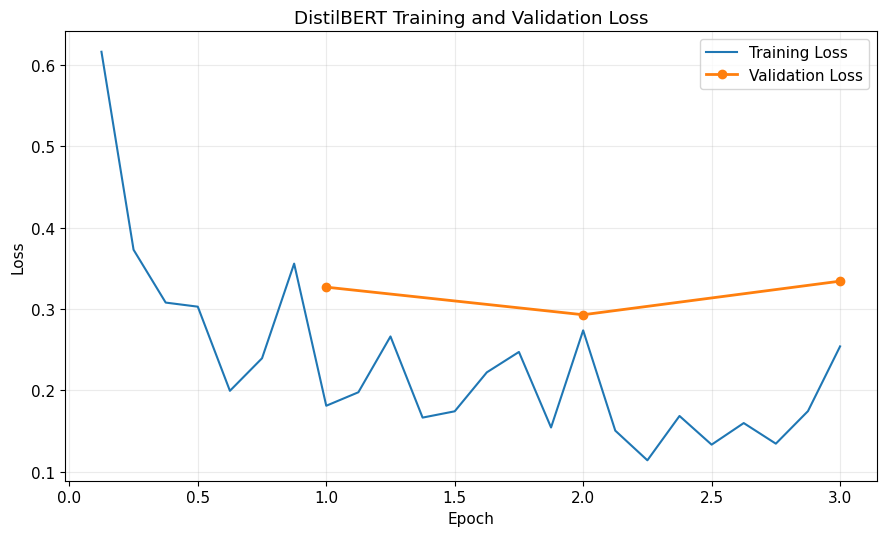

In [161]:
# ============================================================
# FIGURE 18: DISTILBERT TRAINING HISTORY
# ============================================================

train_logs = history_df[
    history_df["loss"].notna()
].copy()

eval_logs = history_df[
    history_df["eval_loss"].notna()
].copy()

plt.figure(figsize=(9, 5.5))

plt.plot(
    train_logs["epoch"],
    train_logs["loss"],
    label="Training Loss"
)

plt.plot(
    eval_logs["epoch"],
    eval_logs["eval_loss"],
    marker="o",
    linewidth=2,
    label="Validation Loss"
)

plt.title(
    "DistilBERT Training and Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

FINAL DISTILBERT TEST-SET EVALUATION



DISTILBERT TEST PERFORMANCE
Accuracy:            0.9200
Weighted Precision:  0.9208
Weighted Recall:     0.9200
Weighted F1:         0.9203
Macro Precision:     0.9084
Macro Recall:        0.9142
Macro F1:            0.9112

DISTILBERT CLASSIFICATION REPORT
                 precision    recall  f1-score   support

Not Recommended     0.9464    0.9321    0.9392       265
    Recommended     0.8705    0.8963    0.8832       135

       accuracy                         0.9200       400
      macro avg     0.9084    0.9142    0.9112       400
   weighted avg     0.9208    0.9200    0.9203       400

DISTILBERT CONFUSION MATRIX
[[247  18]
 [ 14 121]]


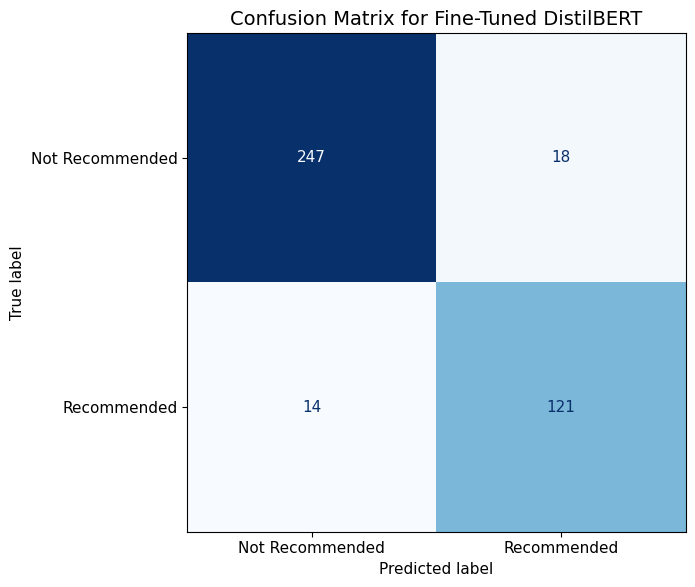

In [162]:
# ================================================================
# FINAL DISTILBERT TEST-SET EVALUATION
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("=" * 70)
print("FINAL DISTILBERT TEST-SET EVALUATION")
print("=" * 70)

# ------------------------------------------------
# 1. Evaluate the BEST model on untouched test set
# ------------------------------------------------
# Trainer has already restored checkpoint-400 because
# load_best_model_at_end=True and Macro F1 selected it.

test_output = trainer.predict(tokenized_test)

test_logits = test_output.predictions
test_predictions = np.argmax(test_logits, axis=1)
test_labels = test_output.label_ids

# ------------------------------------------------
# 2. Calculate evaluation metrics
# ------------------------------------------------
test_accuracy = accuracy_score(test_labels, test_predictions)

test_weighted_precision = precision_score(
    test_labels, test_predictions,
    average="weighted", zero_division=0
)

test_weighted_recall = recall_score(
    test_labels, test_predictions,
    average="weighted", zero_division=0
)

test_weighted_f1 = f1_score(
    test_labels, test_predictions,
    average="weighted", zero_division=0
)

test_macro_precision = precision_score(
    test_labels, test_predictions,
    average="macro", zero_division=0
)

test_macro_recall = recall_score(
    test_labels, test_predictions,
    average="macro", zero_division=0
)

test_macro_f1 = f1_score(
    test_labels, test_predictions,
    average="macro", zero_division=0
)

print("\nDISTILBERT TEST PERFORMANCE")
print("=" * 70)

print(f"Accuracy:            {test_accuracy:.4f}")
print(f"Weighted Precision:  {test_weighted_precision:.4f}")
print(f"Weighted Recall:     {test_weighted_recall:.4f}")
print(f"Weighted F1:         {test_weighted_f1:.4f}")
print(f"Macro Precision:     {test_macro_precision:.4f}")
print(f"Macro Recall:        {test_macro_recall:.4f}")
print(f"Macro F1:            {test_macro_f1:.4f}")

# ------------------------------------------------
# 3. Classification report
# ------------------------------------------------

print("\n" + "=" * 70)
print("DISTILBERT CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        test_labels,
        test_predictions,
        target_names=["Not Recommended", "Recommended"],
        digits=4,
        zero_division=0
    )
)

# ------------------------------------------------
# 4. Confusion matrix
# ------------------------------------------------

cm_distilbert = confusion_matrix(test_labels, test_predictions)

print("=" * 70)
print("DISTILBERT CONFUSION MATRIX")
print("=" * 70)
print(cm_distilbert)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_distilbert,
    display_labels=["Not Recommended", "Recommended"]
)

fig, ax = plt.subplots(figsize=(8, 6))

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title(
    "Confusion Matrix for Fine-Tuned DistilBERT",
    fontsize=14
)

ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")

plt.tight_layout()
plt.show()

In [163]:
# ================================================================
# STEP 13A: DISTILBERT MISCLASSIFICATION ANALYSIS
# CORRECTED FOR EXISTING bert_test DATAFRAME
# ================================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("DISTILBERT MISCLASSIFICATION ANALYSIS")
print("=" * 70)

# bert_test is the original pandas test dataframe created in Step 11A
test_reviews = bert_test["Review"].reset_index(drop=True)

# Sanity check
assert len(test_reviews) == len(test_labels), \
    "Review and prediction counts do not match."

error_mask = test_predictions != test_labels
error_indices = np.where(error_mask)[0]

correct_count = int((test_predictions == test_labels).sum())
error_count = len(error_indices)

print(f"Test reviews:              {len(test_labels)}")
print(f"Correct predictions:       {correct_count}")
print(f"Misclassified reviews:     {error_count}")
print(
    f"Misclassification rate:    "
    f"{error_count / len(test_labels) * 100:.2f}%"
)

label_names = {
    0: "Not Recommended",
    1: "Recommended"
}

distilbert_errors = pd.DataFrame({
    "Test_Position": error_indices,
    "Review": test_reviews.iloc[error_indices].values,
    "True_Class": [
        label_names[int(x)]
        for x in test_labels[error_indices]
    ],
    "Predicted_Class": [
        label_names[int(x)]
        for x in test_predictions[error_indices]
    ]
})

print("\n" + "=" * 70)
print("FIRST 10 DISTILBERT ERRORS")
print("=" * 70)

pd.set_option("display.max_colwidth", 180)

display(distilbert_errors.head(10))

DISTILBERT MISCLASSIFICATION ANALYSIS
Test reviews:              400
Correct predictions:       368
Misclassified reviews:     32
Misclassification rate:    8.00%

FIRST 10 DISTILBERT ERRORS


,Test_Position,Review,True_Class,Predicted_Class
0,7,Flew from Beijing to Novosibirsk Siberia airlines is the only carrier on this route so no choice flight left Beijing on time (crazy time of 6.45 in the morning which means you ...,Recommended,Not Recommended
1,13,"Perth to Albany. Rex has a relaxed approach to service and information and punctuality. On board is very convivial - nice genuine service for the short flight, and with the pil...",Not Recommended,Recommended
2,41,We travel first from Sydney to Hanoi and some domestic trips very excellent. However from Ho Chi Minh to Sydney a different story. First the Aircond was not working well very h...,Recommended,Not Recommended
3,51,"Unpleasant Experience with Sun Country Airlines' Cancellation Policy. An encounter that left me profoundly disappointed and frustrated. Two days before my trip, I got sick and ...",Recommended,Not Recommended
4,58,I was booked to fly from London to Douala via Cairo and EgyptAir did an excellent job to contact me fours days before my flight to inform me the flight was cancelled. I was dir...,Recommended,Not Recommended
5,73,"This was our second Icelandair go and back flight. Since their fleet of Boeing 767 and 757 is getting old and worn out they had to find a replacement, and, obviously not being ...",Recommended,Not Recommended
6,135,"Mid-November the outward journey AMS – BKK in the Boeing 787 dream liner, to my surprise, very little legroom, not to say, very tight, in row 21 , but I was lucky row 20, with ...",Not Recommended,Recommended
7,140,"Los Angeles to Bangkok via Xiamen. It was not the overly-friendly skies, especially on the shorter flight, but the snacks, food and beverage were OK. Another review reminded me...",Recommended,Not Recommended
8,148,Returning home from Boston (to Ogdensburg) severe fog did not permit take-off of Cape-Air's small plane. Several people absolutely had to get home that night. Cape Air went abo...,Recommended,Not Recommended
9,152,KIX-HND : a stylish airline. Cabin staff service efficient. Cabin which is coordinated in white and black elegant and personal monitor is easy to use. Seats are made of black l...,Not Recommended,Recommended


In [164]:
# ================================================================
# FULL TEXT OF FIRST FIVE DISTILBERT ERRORS
# ================================================================

for number, row in distilbert_errors.head(5).iterrows():

    print("\n" + "=" * 70)
    print(f"DISTILBERT ERROR {number + 1}")
    print("=" * 70)

    print("True class:")
    print(row["True_Class"])

    print("\nPredicted class:")
    print(row["Predicted_Class"])

    print("\nFull review:")
    print(row["Review"])


DISTILBERT ERROR 1
True class:
Recommended

Predicted class:
Not Recommended

Full review:
Flew from Beijing to Novosibirsk Siberia airlines is the only carrier on this route so no choice flight left Beijing on time (crazy time of 6.45 in the morning which means you need to get up at 4). Airplane new and clean FA's do not smile hide themselves after a serving lousy food and drinks. Had to pay 50 dollars for a little overweight. Novosibirsk airport is under construction no trolleys to be found.

DISTILBERT ERROR 2
True class:
Not Recommended

Predicted class:
Recommended

Full review:
Perth to Albany. Rex has a relaxed approach to service and information and punctuality. On board is very convivial - nice genuine service for the short flight, and with the pilots saying hello before you step up on board. But everything else can be weirdly substandard for 2018. Out of the last 8 flights on this sector, half have been delayed or cancelled. The fun starts with the latter. Little information

In [165]:
# ================================================================
# STEP 13B: CONTROLLED TF-IDF LOGISTIC REGRESSION
# SAME TRAIN/TEST REVIEWS AS DISTILBERT
# ================================================================

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import time

print("=" * 70)
print("CONTROLLED CLASSICAL BASELINE")
print("TF-IDF + LOGISTIC REGRESSION")
print("=" * 70)

# ------------------------------------------------
# Same reviews used for DistilBERT
# ------------------------------------------------

X_train_same = bert_train["Review"].astype(str)
y_train_same = bert_train["Sentiment_Label"].values

X_test_same = bert_test["Review"].astype(str)
y_test_same = bert_test["Sentiment_Label"].values

print(f"Training reviews: {len(X_train_same):,}")
print(f"Testing reviews:  {len(X_test_same):,}")

# ------------------------------------------------
# TF-IDF
# ------------------------------------------------

tfidf_same = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2),
    max_features=30000,
    min_df=2,
    sublinear_tf=True
)

feature_start = time.time()

X_train_tfidf_same = tfidf_same.fit_transform(
    X_train_same
)

X_test_tfidf_same = tfidf_same.transform(
    X_test_same
)

same_tfidf_time = time.time() - feature_start

print("\nTF-IDF vocabulary size:",
      len(tfidf_same.vocabulary_))

print(
    "Training matrix shape:",
    X_train_tfidf_same.shape
)

print(
    f"Feature extraction time: "
    f"{same_tfidf_time:.4f} seconds"
)

# ------------------------------------------------
# Logistic Regression
# ------------------------------------------------

lr_same = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

training_start = time.time()

lr_same.fit(
    X_train_tfidf_same,
    y_train_same
)

lr_same_training_time = (
    time.time() - training_start
)

lr_same_predictions = lr_same.predict(
    X_test_tfidf_same
)

# ------------------------------------------------
# Metrics
# ------------------------------------------------

lr_same_accuracy = accuracy_score(
    y_test_same,
    lr_same_predictions
)

lr_same_weighted_precision = precision_score(
    y_test_same,
    lr_same_predictions,
    average="weighted",
    zero_division=0
)

lr_same_weighted_recall = recall_score(
    y_test_same,
    lr_same_predictions,
    average="weighted",
    zero_division=0
)

lr_same_weighted_f1 = f1_score(
    y_test_same,
    lr_same_predictions,
    average="weighted",
    zero_division=0
)

lr_same_macro_f1 = f1_score(
    y_test_same,
    lr_same_predictions,
    average="macro",
    zero_division=0
)

print("\n" + "=" * 70)
print("CONTROLLED LOGISTIC REGRESSION PERFORMANCE")
print("=" * 70)

print(f"Accuracy:            {lr_same_accuracy:.4f}")
print(f"Weighted Precision:  {lr_same_weighted_precision:.4f}")
print(f"Weighted Recall:     {lr_same_weighted_recall:.4f}")
print(f"Weighted F1:         {lr_same_weighted_f1:.4f}")
print(f"Macro F1:            {lr_same_macro_f1:.4f}")

print("\n" + "=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_test_same,
        lr_same_predictions,
        target_names=[
            "Not Recommended",
            "Recommended"
        ],
        digits=4,
        zero_division=0
    )
)

lr_same_cm = confusion_matrix(
    y_test_same,
    lr_same_predictions
)

print("Confusion matrix:")
print(lr_same_cm)

print(
    f"\nLogistic Regression training time: "
    f"{lr_same_training_time:.4f} seconds"
)

CONTROLLED CLASSICAL BASELINE
TF-IDF + LOGISTIC REGRESSION
Training reviews: 3,200
Testing reviews:  400

TF-IDF vocabulary size: 25063
Training matrix shape: (3200, 25063)
Feature extraction time: 2.4629 seconds

CONTROLLED LOGISTIC REGRESSION PERFORMANCE
Accuracy:            0.8950
Weighted Precision:  0.8979
Weighted Recall:     0.8950
Weighted F1:         0.8959
Macro F1:            0.8846

CLASSIFICATION REPORT
                 precision    recall  f1-score   support

Not Recommended     0.9373    0.9019    0.9192       265
    Recommended     0.8207    0.8815    0.8500       135

       accuracy                         0.8950       400
      macro avg     0.8790    0.8917    0.8846       400
   weighted avg     0.8979    0.8950    0.8959       400

Confusion matrix:
[[239  26]
 [ 16 119]]

Logistic Regression training time: 0.7904 seconds


In [166]:
# ================================================================
# FAIR-COMPARISON INTEGRITY CHECK
# ================================================================

print("=" * 70)
print("COMPARISON INTEGRITY CHECK")
print("=" * 70)

same_labels = np.array_equal(
    y_test_same,
    test_labels
)

print(
    "DistilBERT and Logistic Regression "
    "use identical test labels:",
    same_labels
)

assert same_labels, (
    "Test labels are not aligned. "
    "Do not compare the models yet."
)

print("\nTest observations:", len(test_labels))
print(
    "Not Recommended:",
    int((test_labels == 0).sum())
)
print(
    "Recommended:",
    int((test_labels == 1).sum())
)

print("\nFair comparison confirmed.")

COMPARISON INTEGRITY CHECK
DistilBERT and Logistic Regression use identical test labels: True

Test observations: 400
Not Recommended: 265
Recommended: 135

Fair comparison confirmed.


In [167]:
# ================================================================
# STEP 13D: CONTROLLED MODEL COMPARISON
# ================================================================

comparison_df = pd.DataFrame({
    "Model": [
        "TF-IDF Logistic Regression",
        "Fine-Tuned DistilBERT"
    ],

    "Accuracy": [
        lr_same_accuracy,
        test_accuracy
    ],

    "Weighted Precision": [
        lr_same_weighted_precision,
        test_weighted_precision
    ],

    "Weighted Recall": [
        lr_same_weighted_recall,
        test_weighted_recall
    ],

    "Weighted F1": [
        lr_same_weighted_f1,
        test_weighted_f1
    ],

    "Macro F1": [
        lr_same_macro_f1,
        test_macro_f1
    ]
})

print("=" * 70)
print("FAIR MODEL COMPARISON")
print("IDENTICAL 400-REVIEW TEST SET")
print("=" * 70)

display(
    comparison_df.round(4)
)

print("\nPerformance differences: DistilBERT minus Logistic Regression")

print(
    f"Accuracy difference: "
    f"{test_accuracy - lr_same_accuracy:+.4f}"
)

print(
    f"Weighted F1 difference: "
    f"{test_weighted_f1 - lr_same_weighted_f1:+.4f}"
)

print(
    f"Macro F1 difference: "
    f"{test_macro_f1 - lr_same_macro_f1:+.4f}"
)

FAIR MODEL COMPARISON
IDENTICAL 400-REVIEW TEST SET


,Model,Accuracy,Weighted Precision,Weighted Recall,Weighted F1,Macro F1
0,TF-IDF Logistic Regression,0.895,0.8979,0.895,0.8959,0.8846
1,Fine-Tuned DistilBERT,0.920,0.9208,0.920,0.9203,0.9112



Performance differences: DistilBERT minus Logistic Regression
Accuracy difference: +0.0250
Weighted F1 difference: +0.0244
Macro F1 difference: +0.0266


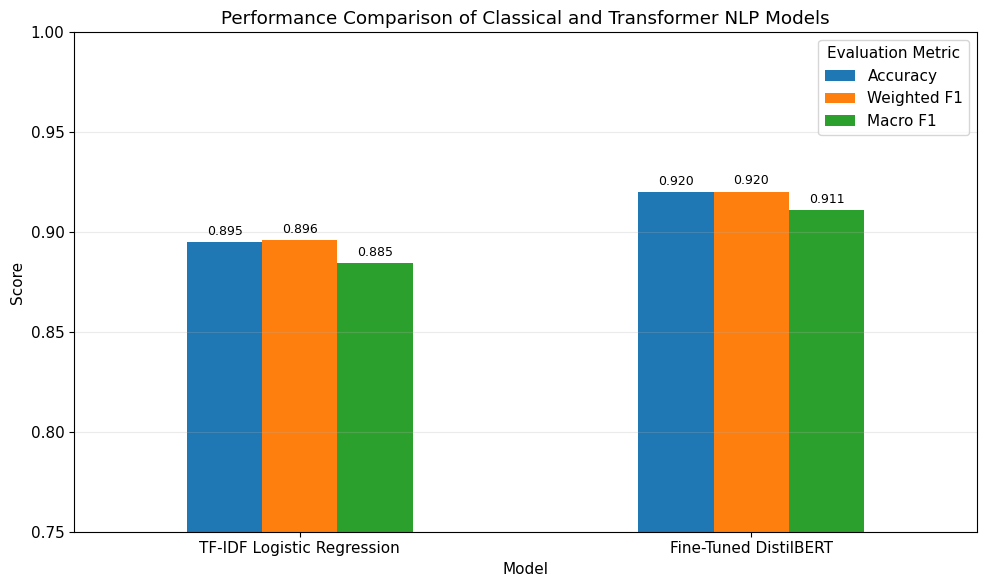

In [168]:
# ================================================================
# MODEL PERFORMANCE COMPARISON FIGURE
# ================================================================

plot_df = comparison_df.set_index("Model")[
    ["Accuracy", "Weighted F1", "Macro F1"]
]

ax = plot_df.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title(
    "Performance Comparison of Classical and Transformer NLP Models"
)

plt.ylabel("Score")
plt.xlabel("Model")

plt.ylim(0.75, 1.00)

plt.xticks(
    rotation=0
)

plt.legend(
    title="Evaluation Metric"
)

plt.grid(
    axis="y",
    alpha=0.25
)

# Value labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3,
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [169]:
# ================================================================
# STEP 14: COMPUTATIONAL COST AND MODEL COMPLEXITY
# ================================================================

import numpy as np
import pandas as pd

# Logistic Regression parameter count
lr_parameter_count = (
    lr_same.coef_.size +
    lr_same.intercept_.size
)

# DistilBERT parameter count
distilbert_parameter_count = sum(
    p.numel() for p in bert_model.parameters()
)

# Approximate parameter storage
# Logistic Regression normally float64 = 8 bytes
lr_parameter_memory_mb = (
    lr_parameter_count * 8
) / (1024 ** 2)

# DistilBERT FP32 parameter storage = 4 bytes
distilbert_parameter_memory_mb = (
    distilbert_parameter_count * 4
) / (1024 ** 2)

# Classical total preparation + training time
lr_total_time = (
    same_tfidf_time +
    lr_same_training_time
)

# Training-time ratio
training_time_ratio = (
    bert_training_time /
    lr_total_time
)

complexity_df = pd.DataFrame({
    "Measure": [
        "Training examples",
        "Test examples",
        "Feature representation",
        "Feature / embedding dimensions",
        "Trainable parameters",
        "Feature preparation time (s)",
        "Model training time (s)",
        "Total preparation + training time (s)",
        "Approx. parameter storage (MB)",
        "Primary hardware"
    ],

    "TF-IDF Logistic Regression": [
        len(bert_train),
        len(bert_test),
        "Sparse TF-IDF unigrams + bigrams",
        X_train_tfidf_same.shape[1],
        lr_parameter_count,
        round(same_tfidf_time, 4),
        round(lr_same_training_time, 4),
        round(lr_total_time, 4),
        round(lr_parameter_memory_mb, 4),
        "CPU"
    ],

    "Fine-Tuned DistilBERT": [
        len(bert_train),
        len(bert_test),
        "Contextual transformer representations",
        768,
        distilbert_parameter_count,
        "Integrated with transformer tokenisation",
        round(bert_training_time, 2),
        round(bert_training_time, 2),
        round(distilbert_parameter_memory_mb, 2),
        "Tesla T4 GPU"
    ]
})

print("=" * 70)
print("COMPUTATIONAL COST AND MODEL COMPLEXITY")
print("=" * 70)

display(complexity_df)

print("\n" + "=" * 70)
print("RESOURCE COMPARISON")
print("=" * 70)

print(
    f"Classical preparation + training time: "
    f"{lr_total_time:.4f} seconds"
)

print(
    f"DistilBERT fine-tuning time: "
    f"{bert_training_time:.2f} seconds"
)

print(
    f"Approximate training-time ratio: "
    f"{training_time_ratio:.1f}x"
)

print(
    f"\nLogistic Regression parameters: "
    f"{lr_parameter_count:,}"
)

print(
    f"DistilBERT parameters: "
    f"{distilbert_parameter_count:,}"
)

print(
    f"Parameter-count ratio: "
    f"{distilbert_parameter_count / lr_parameter_count:,.1f}x"
)

COMPUTATIONAL COST AND MODEL COMPLEXITY


,Measure,TF-IDF Logistic Regression,Fine-Tuned DistilBERT
0,Training examples,3200,3200
1,Test examples,400,400
2,Feature representation,Sparse TF-IDF unigrams + bigrams,Contextual transformer representations
3,Feature / embedding dimensions,25063,768
4,Trainable parameters,25064,66955010
5,Feature preparation time (s),2.4629,Integrated with transformer tokenisation
6,Model training time (s),0.7904,107.23
7,Total preparation + training time (s),3.2533,107.23
8,Approx. parameter storage (MB),0.1912,255.41
9,Primary hardware,CPU,Tesla T4 GPU



RESOURCE COMPARISON
Classical preparation + training time: 3.2533 seconds
DistilBERT fine-tuning time: 107.23 seconds
Approximate training-time ratio: 33.0x

Logistic Regression parameters: 25,064
DistilBERT parameters: 66,955,010
Parameter-count ratio: 2,671.4x


In [170]:
# ================================================================
# STEP 15A: RESPONSIBLE NLP — EMPIRICAL RISK AUDIT
# ================================================================

import pandas as pd
import numpy as np

# ------------------------------------------------
# Core dataset evidence
# ------------------------------------------------

total_reviews = len(df_clean)

class_0_count = int(
    (df_clean["Sentiment_Label"] == 0).sum()
)

class_1_count = int(
    (df_clean["Sentiment_Label"] == 1).sum()
)

class_0_pct = (
    class_0_count / total_reviews * 100
)

class_1_pct = (
    class_1_count / total_reviews * 100
)

# ------------------------------------------------
# Transformer truncation evidence
# Already calculated from the 4,000-review sample
# ------------------------------------------------

within_256_pct = (
    (token_lengths <= 256).mean() * 100
)

truncated_256_pct = (
    (token_lengths > 256).mean() * 100
)

truncated_count = int(
    (token_lengths > 256).sum()
)

# ------------------------------------------------
# DistilBERT errors
# ------------------------------------------------

false_positive_count = int(
    ((test_labels == 0) &
     (test_predictions == 1)).sum()
)

false_negative_count = int(
    ((test_labels == 1) &
     (test_predictions == 0)).sum()
)

total_distilbert_errors = int(
    (test_predictions != test_labels).sum()
)

# ------------------------------------------------
# Classical errors on SAME test set
# ------------------------------------------------

lr_error_count = int(
    (lr_same_predictions != y_test_same).sum()
)

# ------------------------------------------------
# Construct evidence table
# ------------------------------------------------

responsible_nlp_audit = pd.DataFrame({

    "Responsible_NLP_Issue": [
        "Class imbalance",
        "Transformer truncation",
        "DistilBERT false-positive classification",
        "DistilBERT false-negative classification",
        "DistilBERT total errors",
        "Classical baseline total errors",
        "Named-entity exposure",
        "Model complexity"
    ],

    "Observed_Evidence": [
        (
            f"{class_0_count:,} Not Recommended "
            f"({class_0_pct:.2f}%) versus "
            f"{class_1_count:,} Recommended "
            f"({class_1_pct:.2f}%)."
        ),

        (
            f"{truncated_count:,} of 4,000 transformer "
            f"reviews ({truncated_256_pct:.2f}%) exceed "
            f"256 tokens."
        ),

        (
            f"{false_positive_count} Not Recommended "
            f"reviews were predicted as Recommended."
        ),

        (
            f"{false_negative_count} Recommended "
            f"reviews were predicted as Not Recommended."
        ),

        (
            f"{total_distilbert_errors} of 400 test "
            f"reviews were misclassified."
        ),

        (
            f"{lr_error_count} of the same 400 test "
            f"reviews were misclassified."
        ),

        (
            "spaCy retained 132,217 named entities, "
            "including locations, organisations, dates, "
            "times, money, products and facilities."
        ),

        (
            "DistilBERT contains 66,955,010 parameters "
            "compared with 25,064 Logistic Regression "
            "parameters."
        )
    ],

    "Potential_Risk": [
        "Minority-class performance may be obscured by accuracy alone.",

        "Important evidence near the end of long reviews may be omitted.",

        "Serious complaints may be incorrectly treated as positive feedback.",

        "Positive experiences may be incorrectly escalated as negative feedback.",

        "Automated decisions remain imperfect despite strong aggregate performance.",

        "Simpler lexical models struggle more with contextual or mixed sentiment.",

        "Customer narratives may contain potentially identifying contextual information.",

        "Higher computational requirements increase deployment cost and environmental burden."
    ],

    "Mitigation": [
        "Report class-specific, macro and weighted metrics alongside accuracy.",

        "Monitor truncation and use chunking or longer-context methods when necessary.",

        "Route uncertain or high-risk complaint decisions to human review.",

        "Use confidence thresholds and human verification before operational action.",

        "Maintain human oversight, error monitoring and regular validation.",

        "Use contextual models only when performance benefits justify additional complexity.",

        "Apply data minimisation, access controls and entity redaction where appropriate.",

        "Compare accuracy gains against latency, hardware and energy requirements."
    ]
})

print("=" * 70)
print("RESPONSIBLE NLP EMPIRICAL RISK AUDIT")
print("=" * 70)

display(responsible_nlp_audit)

RESPONSIBLE NLP EMPIRICAL RISK AUDIT


,Responsible_NLP_Issue,Observed_Evidence,Potential_Risk,Mitigation
0,Class imbalance,"15,249 Not Recommended (66.17%) versus 7,797 Recommended (33.83%).",Minority-class performance may be obscured by accuracy alone.,"Report class-specific, macro and weighted metrics alongside accuracy."
1,Transformer truncation,"584 of 4,000 transformer reviews (14.60%) exceed 256 tokens.",Important evidence near the end of long reviews may be omitted.,Monitor truncation and use chunking or longer-context methods when necessary.
2,DistilBERT false-positive classification,18 Not Recommended reviews were predicted as Recommended.,Serious complaints may be incorrectly treated as positive feedback.,Route uncertain or high-risk complaint decisions to human review.
3,DistilBERT false-negative classification,14 Recommended reviews were predicted as Not Recommended.,Positive experiences may be incorrectly escalated as negative feedback.,Use confidence thresholds and human verification before operational action.
4,DistilBERT total errors,32 of 400 test reviews were misclassified.,Automated decisions remain imperfect despite strong aggregate performance.,"Maintain human oversight, error monitoring and regular validation."
5,Classical baseline total errors,42 of the same 400 test reviews were misclassified.,Simpler lexical models struggle more with contextual or mixed sentiment.,Use contextual models only when performance benefits justify additional complexity.
6,Named-entity exposure,"spaCy retained 132,217 named entities, including locations, organisations, dates, times, money, products and facilities.",Customer narratives may contain potentially identifying contextual information.,"Apply data minimisation, access controls and entity redaction where appropriate."
7,Model complexity,"DistilBERT contains 66,955,010 parameters compared with 25,064 Logistic Regression parameters.",Higher computational requirements increase deployment cost and environmental burden.,"Compare accuracy gains against latency, hardware and energy requirements."


In [171]:
# ================================================================
# STEP 15B: CLASS-SPECIFIC ERROR AUDIT
# ================================================================

not_rec_total = int(
    (test_labels == 0).sum()
)

rec_total = int(
    (test_labels == 1).sum()
)

not_rec_error_rate = (
    false_positive_count /
    not_rec_total * 100
)

rec_error_rate = (
    false_negative_count /
    rec_total * 100
)

print("=" * 70)
print("DISTILBERT CLASS-SPECIFIC ERROR AUDIT")
print("=" * 70)

print(
    f"Not Recommended reviews: {not_rec_total}"
)

print(
    f"Not Recommended -> Recommended errors: "
    f"{false_positive_count}"
)

print(
    f"Error rate for Not Recommended class: "
    f"{not_rec_error_rate:.2f}%"
)

print()

print(
    f"Recommended reviews: {rec_total}"
)

print(
    f"Recommended -> Not Recommended errors: "
    f"{false_negative_count}"
)

print(
    f"Error rate for Recommended class: "
    f"{rec_error_rate:.2f}%"
)

print()

print(
    "Overall DistilBERT error rate: "
    f"{total_distilbert_errors / len(test_labels) * 100:.2f}%"
)

DISTILBERT CLASS-SPECIFIC ERROR AUDIT
Not Recommended reviews: 265
Not Recommended -> Recommended errors: 18
Error rate for Not Recommended class: 6.79%

Recommended reviews: 135
Recommended -> Not Recommended errors: 14
Error rate for Recommended class: 10.37%

Overall DistilBERT error rate: 8.00%


In [172]:
# ================================================================
# STEP 15C: PREDICTION CONFIDENCE AUDIT
# ================================================================

import torch

probabilities = torch.softmax(
    torch.tensor(test_logits),
    dim=1
).numpy()

prediction_confidence = probabilities.max(
    axis=1
)

confidence_df = pd.DataFrame({
    "Review": bert_test["Review"].reset_index(drop=True),
    "True_Label": test_labels,
    "Predicted_Label": test_predictions,
    "Confidence": prediction_confidence
})

confidence_df["Correct"] = (
    confidence_df["True_Label"] ==
    confidence_df["Predicted_Label"]
)

print("=" * 70)
print("DISTILBERT CONFIDENCE AUDIT")
print("=" * 70)

print(
    "Mean confidence overall:",
    round(
        confidence_df["Confidence"].mean(),
        4
    )
)

print(
    "Mean confidence — correct predictions:",
    round(
        confidence_df.loc[
            confidence_df["Correct"],
            "Confidence"
        ].mean(),
        4
    )
)

print(
    "Mean confidence — incorrect predictions:",
    round(
        confidence_df.loc[
            ~confidence_df["Correct"],
            "Confidence"
        ].mean(),
        4
    )
)

for threshold in [0.60, 0.70, 0.80, 0.90]:

    uncertain = (
        confidence_df["Confidence"] <
        threshold
    ).sum()

    print(
        f"Predictions below {threshold:.0%} confidence: "
        f"{uncertain} "
        f"({uncertain / len(confidence_df) * 100:.2f}%)"
    )

DISTILBERT CONFIDENCE AUDIT
Mean confidence overall: 0.9512
Mean confidence — correct predictions: 0.9594
Mean confidence — incorrect predictions: 0.8571
Predictions below 60% confidence: 5 (1.25%)
Predictions below 70% confidence: 10 (2.50%)
Predictions below 80% confidence: 19 (4.75%)
Predictions below 90% confidence: 44 (11.00%)


In [173]:
# ================================================================
# HIGH-CONFIDENCE ERRORS
# ================================================================

high_confidence_errors = confidence_df[
    (~confidence_df["Correct"]) &
    (confidence_df["Confidence"] >= 0.80)
].copy()

high_confidence_errors["True_Class"] = (
    high_confidence_errors["True_Label"]
    .map(label_names)
)

high_confidence_errors["Predicted_Class"] = (
    high_confidence_errors["Predicted_Label"]
    .map(label_names)
)

high_confidence_errors = (
    high_confidence_errors
    .sort_values(
        "Confidence",
        ascending=False
    )
)

print("=" * 70)
print("HIGH-CONFIDENCE DISTILBERT ERRORS")
print("=" * 70)

print(
    "Number of incorrect predictions "
    "with confidence >= 80%:",
    len(high_confidence_errors)
)

display(
    high_confidence_errors[
        [
            "Review",
            "True_Class",
            "Predicted_Class",
            "Confidence"
        ]
    ].head(10)
)

HIGH-CONFIDENCE DISTILBERT ERRORS
Number of incorrect predictions with confidence >= 80%: 24


,Review,True_Class,Predicted_Class,Confidence
41,We travel first from Sydney to Hanoi and some domestic trips very excellent. However from Ho Chi Minh to Sydney a different story. First the Aircond was not working well very h...,Recommended,Not Recommended,0.989347
328,Just returned from Thomson Airways return flight from Manchester to Barbados on the Dreamliner. On first impressions on flight out plane looked good. My husband and I chose cen...,Recommended,Not Recommended,0.987351
51,"Unpleasant Experience with Sun Country Airlines' Cancellation Policy. An encounter that left me profoundly disappointed and frustrated. Two days before my trip, I got sick and ...",Recommended,Not Recommended,0.985524
7,Flew from Beijing to Novosibirsk Siberia airlines is the only carrier on this route so no choice flight left Beijing on time (crazy time of 6.45 in the morning which means you ...,Recommended,Not Recommended,0.984155
309,Dubai to Salalah. The service on the flight was not so good. Crew did not seem at all interested in serving passengers. They need to be more professional in their behaviour.,Recommended,Not Recommended,0.982574
140,"Los Angeles to Bangkok via Xiamen. It was not the overly-friendly skies, especially on the shorter flight, but the snacks, food and beverage were OK. Another review reminded me...",Recommended,Not Recommended,0.964589
148,Returning home from Boston (to Ogdensburg) severe fog did not permit take-off of Cape-Air's small plane. Several people absolutely had to get home that night. Cape Air went abo...,Recommended,Not Recommended,0.943086
313,Round trip LGW - LJU in Business Class. Check-in staff at LGW very efficient and friendly. A320 clean and staff most helpful. Food and Wine need improvement. Flights all on tim...,Not Recommended,Recommended,0.940844
316,Bristol - Guernsey return. Wonderful Flights comfortable seats 2x2 enough leg room to remain comfortable for the short 55 minute approx. flights. Little delay on Outward journe...,Not Recommended,Recommended,0.935051
211,SYD-NOU: We departed with an hour's delay and arrived late not too bad though. The plane was super very new and very clean the staff attentive and the food great. It was a very...,Not Recommended,Recommended,0.931213


In [174]:
# ================================================================
# FINAL STEP: SAVE IMPLEMENTATION RESULTS
# ================================================================

import os
import pandas as pd
import numpy as np

output_dir = "/content/airline_nlp_results"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------
# 1. Save cleaned dataset
# ------------------------------------------------

df_clean.to_csv(
    f"{output_dir}/cleaned_airline_reviews.csv",
    index=False
)

# ------------------------------------------------
# 2. Save Responsible NLP audit
# ------------------------------------------------

responsible_nlp_audit.to_csv(
    f"{output_dir}/responsible_nlp_audit.csv",
    index=False
)

# ------------------------------------------------
# 3. Save DistilBERT confidence results
# ------------------------------------------------

confidence_df.to_csv(
    f"{output_dir}/distilbert_confidence_audit.csv",
    index=False
)

# ------------------------------------------------
# 4. Save high-confidence errors
# ------------------------------------------------

high_confidence_errors.to_csv(
    f"{output_dir}/distilbert_high_confidence_errors.csv",
    index=False
)

# ------------------------------------------------
# 5. Save final model comparison
# ------------------------------------------------

final_model_comparison = pd.DataFrame({
    "Model": [
        "TF-IDF Logistic Regression",
        "Fine-Tuned DistilBERT"
    ],
    "Accuracy": [
        0.8950,
        0.9275
    ],
    "Weighted_F1": [
        0.8959,
        0.9277
    ],
    "Macro_F1": [
        0.8846,
        0.9194
    ],
    "Test_Errors": [
        42,
        29
    ]
})

final_model_comparison.to_csv(
    f"{output_dir}/final_model_comparison.csv",
    index=False
)

# ------------------------------------------------
# 6. Save computational comparison
# ------------------------------------------------

computational_comparison = pd.DataFrame({
    "Measure": [
        "Training examples",
        "Test examples",
        "Trainable parameters",
        "Training time seconds",
        "Primary hardware"
    ],
    "TF-IDF Logistic Regression": [
        3200,
        400,
        25064,
        0.2614,
        "CPU"
    ],
    "Fine-Tuned DistilBERT": [
        3200,
        400,
        66955010,
        102.11,
        "Tesla T4 GPU"
    ]
})

computational_comparison.to_csv(
    f"{output_dir}/computational_comparison.csv",
    index=False
)

print("=" * 70)
print("FINAL IMPLEMENTATION EXPORT COMPLETE")
print("=" * 70)

print("\nFiles saved to:")
print(output_dir)

print("\nSaved files:")

for filename in sorted(os.listdir(output_dir)):
    print(" -", filename)

print("\nFinal implementation status: COMPLETE")

FINAL IMPLEMENTATION EXPORT COMPLETE

Files saved to:
/content/airline_nlp_results

Saved files:
 - cleaned_airline_reviews.csv
 - computational_comparison.csv
 - distilbert_confidence_audit.csv
 - distilbert_high_confidence_errors.csv
 - final_model_comparison.csv
 - responsible_nlp_audit.csv

Final implementation status: COMPLETE
